# Detección Automática de Personas en Imágenes Aéreas — SARD Dataset

**Inteligencia Artificial II | Grupo B2 | Periodo 2026-2**  
**Docente:** Luis Carlos Guayacán  
**Integrantes:**

José Miguel Murillo Cediel - 2224644

John Anderson Sotelo - 2224769

Maria Lucero Gomez Pico - 2234520


## Descripción del proyecto

En este proyecto se busca desarrollar y evaluar modelos de Deep Learning capaces de detectar y localizar personas en imágenes aéreas capturadas mediante drones, con aplicación en escenarios de búsqueda y rescate.

A diferencia de un problema de clasificación tradicional, en este caso no solamente buscamos determinar si existe una persona en una imagen, sino también localizarla mediante una **caja delimitadora (Bounding Box)**.

Para el desarrollo se utilizarán principalmente los conjuntos de datos **SARD (Search And Rescue Dataset)** y **SARD 2**, disponibles públicamente en Kaggle.

Durante el proyecto se estudiarán las siguientes arquitecturas:

* **YOLOv8:** baseline principal de detección.
* **Faster R-CNN:** detector de dos etapas para comparación.
* **Mask R-CNN:** modelo candidato condicionado a la disponibilidad de máscaras de segmentación, ya que las anotaciones actuales de SARD son bounding boxes.

Las métricas principales de evaluación serán:

* Precision
* Recall
* IoU
* mAP@50
* mAP@50-95


## Problema y Datos

### El problema

En operaciones de búsqueda y rescate, los drones permiten inspeccionar grandes extensiones de terreno en relativamente poco tiempo. Sin embargo, esto genera una gran cantidad de imágenes que posteriormente deben ser revisadas para localizar personas.

La detección manual puede resultar difícil debido a factores como:

* Personas que ocupan pocos píxeles en la imagen.
* Variación de altura y ángulo de captura.
* Vegetación y terrenos complejos.
* Sombras y elementos visualmente similares.
* Diferentes posiciones de las personas.

### Objetivo

El objetivo principal del proyecto es entrenar modelos de Deep Learning capaces de:

1. Identificar la presencia de personas en imágenes aéreas.
2. Localizar cada persona mediante un Bounding Box.
3. Asignar un nivel de confianza a cada detección.
4. Comparar diferentes arquitecturas según precisión y velocidad.

La clase principal del proyecto será:

**Human → Persona**


In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
from pathlib import Path

RUTA_PROYECTO = Path(
    "/content/drive/MyDrive/IA2_SARD"
)
RUTA_PROYECTO.mkdir(
    parents=True,
    exist_ok=True
)
print(RUTA_PROYECTO)


/content/drive/MyDrive/IA2_SARD


In [3]:
#instalacion de librerias necesarias

!pip install -q ultralytics
!pip install -q kagglehub


In [4]:
#manejo de archivos y carpetas
import os
import glob
import shutil
import random
import hashlib
from pathlib import Path

#manejo de datos
import pandas as pd
import numpy as np

#visualizacion
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

#archivos yaml
import yaml

#deep learning
import torch

#YOLO
from ultralytics import YOLO

#descarga de datasets
import kagglehub

#semillas para reproducibilidad
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

print("==================================================")
print(" LIBRERÍAS CARGADAS CORRECTAMENTE")
print("==================================================")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
 LIBRERÍAS CARGADAS CORRECTAMENTE


In [5]:
#verificar disponibilidad de GPU

print("==================================================")
print(" INFORMACIÓN DEL ENTORNO")
print("==================================================")

print(f"PyTorch: {torch.__version__}")
print(f"GPU disponible: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU utilizada: {torch.cuda.get_device_name(0)}")
else:
    print("No se detectó GPU. Revisar el entorno de ejecución de Colab.")


 INFORMACIÓN DEL ENTORNO
PyTorch: 2.11.0+cu130
GPU disponible: True
GPU utilizada: Tesla T4


## Descarga de los Conjuntos de Datos

Para el proyecto utilizaremos dos conjuntos de datos públicos disponibles en Kaggle:

### SARD — Search And Rescue Dataset

Será utilizado como el conjunto de datos principal para construir el primer modelo de detección.

La clase principal es:

* `Human`

### SARD 2 — Extra Classes

Será utilizado posteriormente como conjunto complementario. Este dataset contiene diferentes estados o posturas humanas, que podrán remapearse a una única clase `Human`.

Inicialmente NO fusionaremos ambos datasets.

Primero analizaremos y entrenaremos un modelo base utilizando únicamente SARD. Posteriormente estudiaremos si incorporar SARD 2 produce una mejora real en el desempeño.


In [6]:
#descargar dataset principal SARD

print("==================================================")
print(" DESCARGANDO SARD")
print("==================================================")

ruta_sard = kagglehub.dataset_download(
    "nikolasgegenava/sard-search-and-rescue"
)

print("\nDataset descargado correctamente.")
print(f"Ruta SARD: {ruta_sard}")


 DESCARGANDO SARD
Using Colab cache for faster access to the 'sard-search-and-rescue' dataset.

Dataset descargado correctamente.
Ruta SARD: /kaggle/input/sard-search-and-rescue


In [7]:
#descargar dataset complementario SARD 2

print("==================================================")
print(" DESCARGANDO SARD 2")
print("==================================================")

ruta_sard2 = kagglehub.dataset_download(
    "nikolasgegenava/sard-2-search-and-rescue-dataset-extra-classes"
)

print("\nDataset descargado correctamente.")
print(f"Ruta SARD 2: {ruta_sard2}")


 DESCARGANDO SARD 2


100%|██████████| 1.24G/1.24G [01:13<00:00, 18.1MB/s]

Extracting files...



Dataset descargado correctamente.
Ruta SARD 2: /root/.cache/kagglehub/datasets/nikolasgegenava/sard-2-search-and-rescue-dataset-extra-classes/versions/1


## Exploración Inicial de la Estructura de los Datos

Antes de realizar cualquier transformación o entrenamiento debemos conocer cómo están organizados los archivos.

En un problema de detección de objetos normalmente encontramos dos elementos principales:

* **Imágenes:** contienen las escenas utilizadas como entrada del modelo.
* **Labels:** archivos que contienen las anotaciones de cada objeto presente en la imagen.

En el formato YOLO, cada objeto suele representarse mediante información asociada a:

`clase + coordenadas del Bounding Box`

Primero inspeccionaremos la estructura de directorios de SARD y SARD 2 para confirmar dónde se encuentran las imágenes y sus respectivas anotaciones.


In [8]:
#funcion para visualizar la estructura de carpetas

def mostrar_estructura(ruta, profundidad_maxima=3):

    ruta = Path(ruta)

    print(f"\nESTRUCTURA DE: {ruta}")
    print("=" * 70)

    for raiz, carpetas, archivos in os.walk(ruta):

        nivel = len(Path(raiz).relative_to(ruta).parts)

        if nivel > profundidad_maxima:
            continue

        sangria = "    " * nivel
        print(f"{sangria}📁 {Path(raiz).name}/")

        #mostrar solamente algunos archivos como ejemplo
        for archivo in archivos[:5]:
            print(f"{sangria}    📄 {archivo}")

        if len(archivos) > 5:
            print(f"{sangria}    ... {len(archivos)-5} archivos adicionales")


In [ ]:
print("==================================================")
print(" ESTRUCTURA DEL DATASET SARD")
print("==================================================")

mostrar_estructura(ruta_sard)


print("\n\n==================================================")
print(" ESTRUCTURA DEL DATASET SARD 2")
print("==================================================")

mostrar_estructura(ruta_sard2)


 ESTRUCTURA DEL DATASET SARD

ESTRUCTURA DE: /root/.cache/kagglehub/datasets/nikolasgegenava/sard-search-and-rescue/versions/1
📁 1/
    📁 search-and-rescue/
        📄 README.dataset.txt
        📄 data.yaml
        📄 README.roboflow.txt
        📁 train/
            📁 labels/
                📄 gss1013_jpg.rf.ba65f29097f0cc2b233d87eca8834f82.txt
                📄 gss1800_jpg.rf.7dda808890e85b4f6546b6029e12c2e4.txt
                📄 gss1308_jpg.rf.79a3b6e5e934383392a0b708a173dc68.txt
                📄 gss1645_jpg.rf.cabef09bd34553156cee47a293d0f75b.txt
                📄 gss1558_jpg.rf.4bd87970cfc9cd382d9e648e6e1c5672.txt
                ... 4036 archivos adicionales
            📁 images/
                📄 gss1494_jpg.rf.386f1b2545647326dd1a79ccb0ff4418.jpg
                📄 gss697_jpg.rf.4df29c2d493d9e2b7e0f87c8030540d0.jpg
                📄 gss60_jpg.rf.8b42f3c9447504c5a5beac1c1df7577f.jpg
                📄 gss1489_jpg.rf.47db936309254c268c0b4811bc29db72.jpg
                📄 gss1647_jpg.

In [9]:
#buscar archivos yaml dentro de los datasets

yaml_sard = list(Path(ruta_sard).rglob("*.yaml"))
yaml_sard2 = list(Path(ruta_sard2).rglob("*.yaml"))

print("==================================================")
print(" ARCHIVOS YAML EN SARD")
print("==================================================")

for archivo in yaml_sard:
    print(archivo)


print("\n==================================================")
print(" ARCHIVOS YAML EN SARD 2")
print("==================================================")

for archivo in yaml_sard2:
    print(archivo)


 ARCHIVOS YAML EN SARD
/kaggle/input/sard-search-and-rescue/search-and-rescue/data.yaml

 ARCHIVOS YAML EN SARD 2
/root/.cache/kagglehub/datasets/nikolasgegenava/sard-2-search-and-rescue-dataset-extra-classes/versions/1/search-and-rescue-2/data.yaml


## Exploración del conjunto de datos SARD

Una vez descargado el conjunto de datos, se verificó que SARD ya se encuentra organizado utilizando una estructura compatible con YOLO.

El conjunto contiene tres particiones:

* **Train:** utilizado para ajustar los parámetros del modelo.
* **Validation:** utilizado durante el entrenamiento para evaluar la capacidad de generalización.
* **Test:** utilizado únicamente para realizar la evaluación final.

Cada partición contiene dos carpetas:

* `images`: imágenes aéreas.
* `labels`: anotaciones de los objetos presentes en cada imagen.

Antes de entrenar los modelos realizaremos un análisis exploratorio para verificar la integridad y características del conjunto de datos.


In [18]:
#definir ruta principal del dataset SARD

from pathlib import Path

ruta_base_sard = Path(ruta_sard) / "search-and-rescue"

ruta_train_img = ruta_base_sard / "train" / "images"
ruta_train_lbl = ruta_base_sard / "train" / "labels"

ruta_valid_img = ruta_base_sard / "valid" / "images"
ruta_valid_lbl = ruta_base_sard / "valid" / "labels"

ruta_test_img = ruta_base_sard / "test" / "images"
ruta_test_lbl = ruta_base_sard / "test" / "labels"

print("==================================================")
print(" RUTAS DEL DATASET SARD")
print("==================================================")

print(f"Ruta principal: {ruta_base_sard}")
print(f"Train imágenes: {ruta_train_img}")
print(f"Valid imágenes: {ruta_valid_img}")
print(f"Test imágenes:  {ruta_test_img}")


 RUTAS DEL DATASET SARD
Ruta principal: /kaggle/input/sard-search-and-rescue/search-and-rescue
Train imágenes: /kaggle/input/sard-search-and-rescue/search-and-rescue/train/images
Valid imágenes: /kaggle/input/sard-search-and-rescue/search-and-rescue/valid/images
Test imágenes:  /kaggle/input/sard-search-and-rescue/search-and-rescue/test/images


In [19]:
#visualizar configuracion del archivo data.yaml

ruta_yaml = ruta_base_sard / "data.yaml"

print("==================================================")
print(" CONTENIDO DE data.yaml")
print("==================================================")

with open(ruta_yaml, "r") as archivo:
    contenido_yaml = archivo.read()

print(contenido_yaml)


 CONTENIDO DE data.yaml
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 1
names: ['human']

roboflow:
  workspace: datasets-pdabr
  project: sard-8xjhy
  version: 17
  license: Private
  url: https://universe.roboflow.com/datasets-pdabr/sard-8xjhy/dataset/17


In [21]:
#funcion para contar imagenes y etiquetas

def contar_archivos(ruta_imagenes, ruta_labels):

    extensiones = ["*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG"]

    imagenes = []

    for extension in extensiones:
        imagenes.extend(ruta_imagenes.glob(extension))

    labels = list(ruta_labels.glob("*.txt"))

    return len(imagenes), len(labels)


train_img, train_lbl = contar_archivos(ruta_train_img, ruta_train_lbl)
valid_img, valid_lbl = contar_archivos(ruta_valid_img, ruta_valid_lbl)
test_img, test_lbl = contar_archivos(ruta_test_img, ruta_test_lbl)


print("==================================================")
print(" DISTRIBUCIÓN DEL DATASET")
print("==================================================")

print(f"TRAIN  -> Imágenes: {train_img} | Labels: {train_lbl}")
print(f"VALID  -> Imágenes: {valid_img} | Labels: {valid_lbl}")
print(f"TEST   -> Imágenes: {test_img} | Labels: {test_lbl}")

print("==================================================")
print(f"TOTAL IMÁGENES: {train_img + valid_img + test_img}")
print("==================================================")


 DISTRIBUCIÓN DEL DATASET
TRAIN  -> Imágenes: 4041 | Labels: 4041
VALID  -> Imágenes: 1144 | Labels: 1144
TEST   -> Imágenes: 570 | Labels: 570
TOTAL IMÁGENES: 5755


In [22]:
#crear tabla resumen del dataset

resumen_dataset = pd.DataFrame({
    "Partición": ["Train", "Validation", "Test"],
    "Imágenes": [train_img, valid_img, test_img],
    "Labels": [train_lbl, valid_lbl, test_lbl]
})

resumen_dataset["Porcentaje"] = (
    resumen_dataset["Imágenes"]
    / resumen_dataset["Imágenes"].sum()
    * 100
)

resumen_dataset


,Partición,Imágenes,Labels,Porcentaje
0,Train,4041,4041,70.217202
1,Validation,1144,1144,19.878367
2,Test,570,570,9.904431


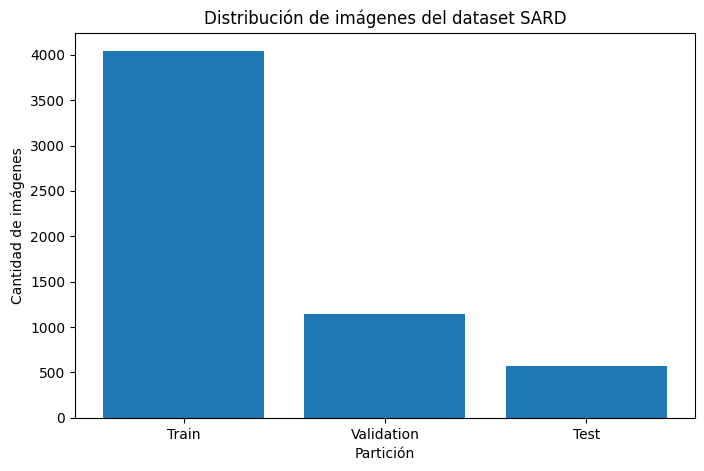

In [23]:
#visualizar distribucion del dataset

plt.figure(figsize=(8,5))

plt.bar(
    resumen_dataset["Partición"],
    resumen_dataset["Imágenes"]
)

plt.title("Distribución de imágenes del dataset SARD")
plt.xlabel("Partición")
plt.ylabel("Cantidad de imágenes")

plt.show()


### Análisis de la distribución

El conjunto de datos SARD contiene un total de **5.755 imágenes**.

La mayor parte de los datos se encuentra destinada al entrenamiento del modelo, mientras que una proporción menor se utiliza para validación y prueba.

Esta distribución permite entrenar los modelos con una cantidad considerable de ejemplos y mantener conjuntos independientes para evaluar su capacidad de generalización.


In [24]:
#verificar correspondencia entre imagenes y etiquetas

def verificar_pares(ruta_imagenes, ruta_labels):

    imagenes = (
        list(ruta_imagenes.glob("*.jpg"))
        + list(ruta_imagenes.glob("*.jpeg"))
        + list(ruta_imagenes.glob("*.png"))
    )

    labels = list(ruta_labels.glob("*.txt"))

    nombres_imagenes = {archivo.stem for archivo in imagenes}
    nombres_labels = {archivo.stem for archivo in labels}

    imagenes_sin_label = nombres_imagenes - nombres_labels
    labels_sin_imagen = nombres_labels - nombres_imagenes

    return imagenes_sin_label, labels_sin_imagen


In [25]:
print(" VERIFICACIÓN IMAGEN - LABEL")

for nombre, img, lbl in [
    ("TRAIN", ruta_train_img, ruta_train_lbl),
    ("VALID", ruta_valid_img, ruta_valid_lbl),
    ("TEST", ruta_test_img, ruta_test_lbl)
]:

    sin_label, sin_imagen = verificar_pares(img, lbl)

    print(f"\n{nombre}")
    print(f"Imágenes sin label: {len(sin_label)}")
    print(f"Labels sin imagen: {len(sin_imagen)}")


 VERIFICACIÓN IMAGEN - LABEL

TRAIN
Imágenes sin label: 0
Labels sin imagen: 0

VALID
Imágenes sin label: 0
Labels sin imagen: 0

TEST
Imágenes sin label: 0
Labels sin imagen: 0


In [26]:
#contar cantidad de personas por imagen

def contar_objetos_por_imagen(ruta_labels):

    datos = []

    for archivo in ruta_labels.glob("*.txt"):

        with open(archivo, "r") as f:
            lineas = [
                linea
                for linea in f.readlines()
                if linea.strip()
            ]

        datos.append({
            "archivo": archivo.name,
            "personas": len(lineas)
        })

    return pd.DataFrame(datos)


objetos_train = contar_objetos_por_imagen(ruta_train_lbl)

objetos_train.head()


,archivo,personas
0,gss1998_jpg.rf.778840cd6b73198a53ff9ef4a8fcd3e...,1
1,gss1031_jpg.rf.13f73ee7c73bfba8ee21d61ab75ba3c...,2
2,gss970_jpg.rf.714bb5068a7dbfc0667e974a98e9d2d0...,1
3,gss1046_jpg.rf.303b5bb84ba5f49ab3368a6a0404a1d...,1
4,gss1202_jpg.rf.09867195832fc7187add5643f177a54...,2


In [27]:
print("==================================================")
print(" PERSONAS POR IMAGEN - TRAIN")
print("==================================================")

print(objetos_train["personas"].describe())


 PERSONAS POR IMAGEN - TRAIN
count    4041.000000
mean        1.293987
std         1.085542
min         0.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         7.000000
Name: personas, dtype: float64


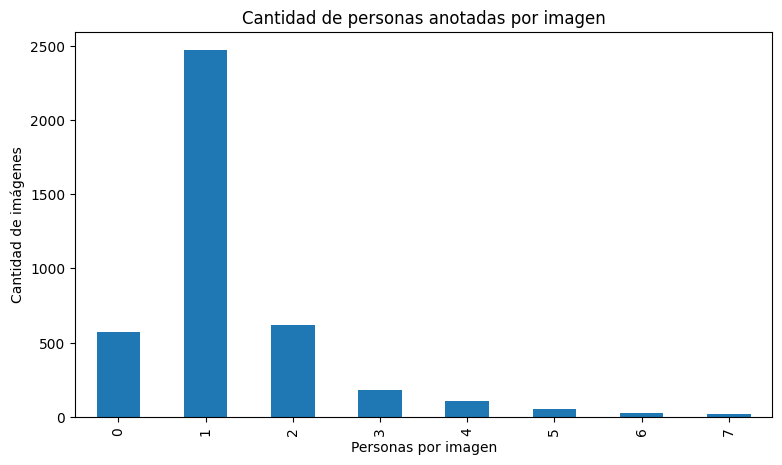

In [28]:
plt.figure(figsize=(9,5))

objetos_train["personas"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Cantidad de personas anotadas por imagen")
plt.xlabel("Personas por imagen")
plt.ylabel("Cantidad de imágenes")

plt.show()


In [29]:
#identificar ids de clase presentes en las anotaciones

clases_encontradas = set()

for archivo in ruta_train_lbl.glob("*.txt"):

    with open(archivo, "r") as f:

        for linea in f:

            if linea.strip():

                clase = int(linea.split()[0])
                clases_encontradas.add(clase)


print("==================================================")
print(" CLASES ENCONTRADAS")
print("==================================================")

print(clases_encontradas)


 CLASES ENCONTRADAS
{0}


In [30]:
#analizar resoluciones de las imagenes

resoluciones = []

imagenes_train = list(ruta_train_img.glob("*.jpg"))

for archivo in imagenes_train:

    with Image.open(archivo) as img:

        ancho, alto = img.size

        resoluciones.append({
            "archivo": archivo.name,
            "ancho": ancho,
            "alto": alto
        })


df_resoluciones = pd.DataFrame(resoluciones)

df_resoluciones.head()


,archivo,ancho,alto
0,gss1151_jpg.rf.1cf53097ffbcd2751bf13cb28cd3a12...,640,640
1,gss2075_jpg.rf.d003c9d7e849714c8a13afd55e188ca...,640,640
2,gss595_jpg.rf.ae44b5f79fa660b36b06b90bac618c4a...,640,640
3,gss756_jpg.rf.eb82d175c656d694a81e9f4ba71b1c4f...,640,640
4,gss1789_jpg.rf.2f65dfc6a450535c76b26ec81692cc3...,640,640


In [31]:
print("==================================================")
print(" RESOLUCIONES")
print("==================================================")

print(df_resoluciones[["ancho", "alto"]].value_counts().head(10))


 RESOLUCIONES
ancho  alto
640    640     4041
Name: count, dtype: int64


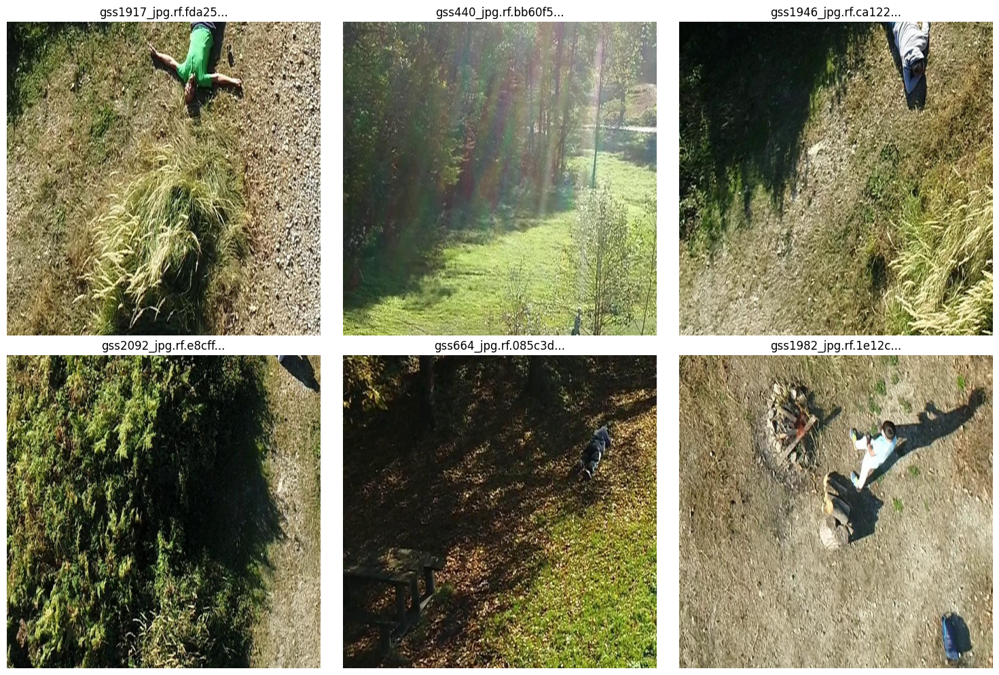

In [32]:
#visualizar ejemplos aleatorios del dataset

imagenes = list(ruta_train_img.glob("*.jpg"))

muestras = random.sample(imagenes, 6)

plt.figure(figsize=(15,10))

for i, archivo in enumerate(muestras):

    img = Image.open(archivo)

    plt.subplot(2,3,i+1)
    plt.imshow(img)
    plt.title(archivo.name[:20] + "...")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [33]:
#funcion para visualizar bounding boxes YOLO

def mostrar_bounding_boxes(ruta_imagen, ruta_label):

    imagen = Image.open(ruta_imagen).convert("RGB")

    ancho_img, alto_img = imagen.size

    dibujo = ImageDraw.Draw(imagen)

    with open(ruta_label, "r") as archivo:

        for linea in archivo:

            datos = linea.strip().split()

            if len(datos) != 5:
                continue

            clase, x_centro, y_centro, ancho, alto = map(float, datos)

            #convertir coordenadas normalizadas a pixeles
            x_centro *= ancho_img
            y_centro *= alto_img

            ancho *= ancho_img
            alto *= alto_img

            #calcular esquinas del bounding box
            x1 = x_centro - ancho / 2
            y1 = y_centro - alto / 2

            x2 = x_centro + ancho / 2
            y2 = y_centro + alto / 2

            dibujo.rectangle(
                [x1, y1, x2, y2],
                outline="red",
                width=3
            )

            dibujo.text(
                (x1, y1),
                "Human",
                fill="red"
            )

    plt.figure(figsize=(10,8))

    plt.imshow(imagen)

    plt.title("Imagen SARD con Bounding Boxes")

    plt.axis("off")

    plt.show()


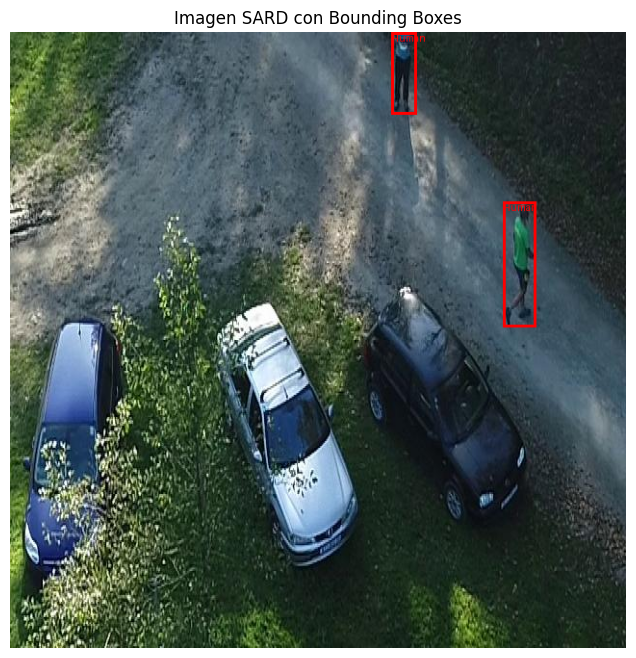

In [34]:
#seleccionar imagen aleatoria

imagen_ejemplo = random.choice(imagenes)

label_ejemplo = ruta_train_lbl / f"{imagen_ejemplo.stem}.txt"

mostrar_bounding_boxes(
    imagen_ejemplo,
    label_ejemplo
)


# Continuación metodológica

Hasta este punto ya se verificó la estructura del dataset SARD, su distribución en entrenamiento, validación y prueba, la correspondencia entre imágenes y labels, la clase presente, la resolución de las imágenes y la visualización de bounding boxes.

A partir de aquí el desarrollo se divide en las siguientes fases:

1. **Cerrar el análisis exploratorio de SARD.**
2. **Corregir el archivo de configuración `data.yaml`.**
3. **Entrenar un baseline con YOLOv8n.**
4. **Evaluar YOLOv8 sobre el conjunto de test.**
5. **Entrenar y evaluar Faster R-CNN sobre las mismas particiones.**
6. **Comprobar la viabilidad de Mask R-CNN.**
7. **Analizar SARD 2 y verificar posibles solapamientos con SARD.**
8. **Realizar un experimento SARD vs. SARD + SARD 2 remapeado a `Human`.**
9. **Comparar modelos mediante las mismas métricas de detección y velocidad.**


## 1. Verificación del formato de las anotaciones

Las anotaciones del dataset están almacenadas en formato YOLO. Cada línea representa una instancia y contiene:

`clase  x_center  y_center  width  height`

Las cuatro coordenadas están normalizadas entre 0 y 1.

Antes de entrenar se verificará que las anotaciones cumplan este formato y que la clase utilizada corresponda a `0 = Human`.


In [35]:
#mostrar una anotacion de ejemplo y validar el formato YOLO

archivo_label_ejemplo = next(ruta_train_lbl.glob("*.txt"))

print("==================================================")
print(" EJEMPLO DE ANOTACIÓN YOLO")
print("==================================================")
print(f"Archivo: {archivo_label_ejemplo.name}\n")

with open(archivo_label_ejemplo, "r") as archivo:
    lineas = [linea.strip() for linea in archivo if linea.strip()]

for linea in lineas[:10]:
    print(linea)

errores_formato = []

for particion, ruta_labels in [
    ("train", ruta_train_lbl),
    ("valid", ruta_valid_lbl),
    ("test", ruta_test_lbl)
]:
    for archivo in ruta_labels.glob("*.txt"):
        with open(archivo, "r") as f:
            for numero_linea, linea in enumerate(f, start=1):
                if not linea.strip():
                    continue

                datos = linea.split()

                if len(datos) != 5:
                    errores_formato.append((particion, archivo.name, numero_linea, "cantidad_campos"))
                    continue

                clase = int(float(datos[0]))
                coords = list(map(float, datos[1:]))

                if clase != 0:
                    errores_formato.append((particion, archivo.name, numero_linea, "clase_distinta_0"))

                if not all(0 <= valor <= 1 for valor in coords):
                    errores_formato.append((particion, archivo.name, numero_linea, "coordenada_fuera_rango"))

print("\n==================================================")
print(" VALIDACIÓN DEL FORMATO")
print("==================================================")
print(f"Errores encontrados: {len(errores_formato)}")

if errores_formato:
    print("Primeros errores:")
    print(errores_formato[:10])
else:
    print("Todas las anotaciones revisadas cumplen el formato esperado.")


 EJEMPLO DE ANOTACIÓN YOLO
Archivo: gss1998_jpg.rf.778840cd6b73198a53ff9ef4a8fcd3e6.txt

0 0.97578125 0.7984375 0.0484375 0.153125

 VALIDACIÓN DEL FORMATO
Errores encontrados: 0
Todas las anotaciones revisadas cumplen el formato esperado.


## 2. Análisis del tamaño de los objetos

Una dificultad central del proyecto es la detección de personas pequeñas dentro de imágenes aéreas.

Para comprobarlo cuantitativamente se calcularán, para cada bounding box:

* Ancho y alto normalizados.
* Ancho y alto en píxeles.
* Área del bounding box en píxeles.
* Porcentaje de la imagen ocupado por la persona.

Este análisis permitirá sustentar con datos si el problema corresponde efectivamente a detección de objetos pequeños.


In [36]:
#crear dataframe con todas las anotaciones y tamaños de bounding boxes

def obtener_imagenes(ruta):
    extensiones = ["*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG"]
    archivos = []
    for extension in extensiones:
        archivos.extend(ruta.glob(extension))
    return archivos


def construir_dataframe_anotaciones(nombre_particion, ruta_imagenes, ruta_labels):
    registros = []

    for imagen_path in obtener_imagenes(ruta_imagenes):

        label_path = ruta_labels / f"{imagen_path.stem}.txt"

        with Image.open(imagen_path) as img:
            ancho_img, alto_img = img.size

        if not label_path.exists():
            continue

        with open(label_path, "r") as archivo:
            lineas = [linea.strip() for linea in archivo if linea.strip()]

        for indice_objeto, linea in enumerate(lineas):
            clase, xc, yc, w, h = map(float, linea.split())

            ancho_px = w * ancho_img
            alto_px = h * alto_img
            area_px = ancho_px * alto_px
            area_pct = (w * h) * 100

            registros.append({
                "particion": nombre_particion,
                "imagen": imagen_path.name,
                "objeto": indice_objeto,
                "clase": int(clase),
                "x_center": xc,
                "y_center": yc,
                "width_norm": w,
                "height_norm": h,
                "width_px": ancho_px,
                "height_px": alto_px,
                "area_px": area_px,
                "area_pct": area_pct,
                "ancho_imagen": ancho_img,
                "alto_imagen": alto_img
            })

    return pd.DataFrame(registros)


df_train_boxes = construir_dataframe_anotaciones(
    "train", ruta_train_img, ruta_train_lbl
)

df_valid_boxes = construir_dataframe_anotaciones(
    "valid", ruta_valid_img, ruta_valid_lbl
)

df_test_boxes = construir_dataframe_anotaciones(
    "test", ruta_test_img, ruta_test_lbl
)

df_boxes = pd.concat(
    [df_train_boxes, df_valid_boxes, df_test_boxes],
    ignore_index=True
)

print("==================================================")
print(" ANOTACIONES TOTALES")
print("==================================================")
print(f"Bounding boxes totales: {len(df_boxes)}")
print(f"Train: {len(df_train_boxes)}")
print(f"Valid: {len(df_valid_boxes)}")
print(f"Test: {len(df_test_boxes)}")

df_boxes.head()


 ANOTACIONES TOTALES
Bounding boxes totales: 7424
Train: 5229
Valid: 1463
Test: 732


,particion,imagen,objeto,clase,x_center,y_center,width_norm,height_norm,width_px,height_px,area_px,area_pct,ancho_imagen,alto_imagen
0,train,gss1151_jpg.rf.1cf53097ffbcd2751bf13cb28cd3a12...,0,0,0.803906,0.565625,0.057813,0.130469,37.0,83.5,3089.5,0.754272,640,640
1,train,gss2075_jpg.rf.d003c9d7e849714c8a13afd55e188ca...,0,0,0.982031,0.387500,0.035937,0.208594,23.0,133.5,3070.5,0.749634,640,640
2,train,gss2075_jpg.rf.d003c9d7e849714c8a13afd55e188ca...,1,0,0.898438,0.953906,0.109375,0.091406,70.0,58.5,4095.0,0.999756,640,640
3,train,gss595_jpg.rf.ae44b5f79fa660b36b06b90bac618c4a...,0,0,0.163281,0.203906,0.020313,0.103125,13.0,66.0,858.0,0.209473,640,640
4,train,gss756_jpg.rf.eb82d175c656d694a81e9f4ba71b1c4f...,0,0,0.778906,0.744531,0.326562,0.355469,209.0,227.5,47547.5,11.608276,640,640


In [37]:
#resumen estadistico del tamaño de las personas

print("==================================================")
print(" TAMAÑO DE LOS BOUNDING BOXES")
print("==================================================")

columnas = ["width_px", "height_px", "area_px", "area_pct"]

display(df_boxes[columnas].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95]))

mediana_area = df_boxes["area_pct"].median()
p90_area = df_boxes["area_pct"].quantile(0.90)

pct_menor_1 = (df_boxes["area_pct"] < 1).mean() * 100
pct_menor_5 = (df_boxes["area_pct"] < 5).mean() * 100

print(f"\nMediana del área ocupada: {mediana_area:.4f}%")
print(f"Percentil 90 del área ocupada: {p90_area:.4f}%")
print(f"Bounding boxes que ocupan menos del 1% de la imagen: {pct_menor_1:.2f}%")
print(f"Bounding boxes que ocupan menos del 5% de la imagen: {pct_menor_5:.2f}%")


 TAMAÑO DE LOS BOUNDING BOXES


,width_px,height_px,area_px,area_pct
count,7424.000000,7424.000000,7424.000000,7424.000000
mean,46.087419,94.550647,5253.413591,1.282572
std,35.914875,52.756871,7831.621716,1.912017
min,1.000000,2.000000,10.000000,0.002441
10%,16.000000,42.500000,832.600000,0.203271
25%,23.000000,58.500000,1419.500000,0.346558
50%,36.000000,82.000000,2860.000000,0.698242
75%,57.000000,119.000000,5841.250000,1.426086
90%,90.000000,160.000000,11747.750000,2.868103
95%,114.000000,201.000000,17440.650000,4.257971



Mediana del área ocupada: 0.6982%
Percentil 90 del área ocupada: 2.8681%
Bounding boxes que ocupan menos del 1% de la imagen: 63.44%
Bounding boxes que ocupan menos del 5% de la imagen: 96.05%


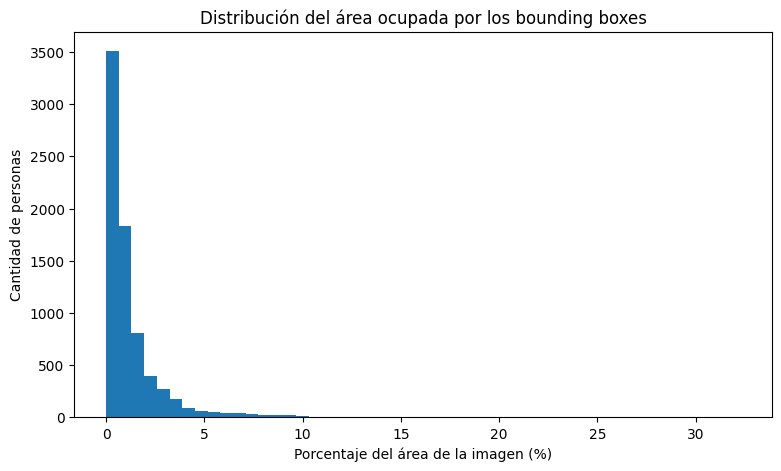

In [38]:
#distribucion del porcentaje de imagen ocupado por las personas

plt.figure(figsize=(9,5))

plt.hist(
    df_boxes["area_pct"],
    bins=50
)

plt.title("Distribución del área ocupada por los bounding boxes")
plt.xlabel("Porcentaje del área de la imagen (%)")
plt.ylabel("Cantidad de personas")

plt.show()


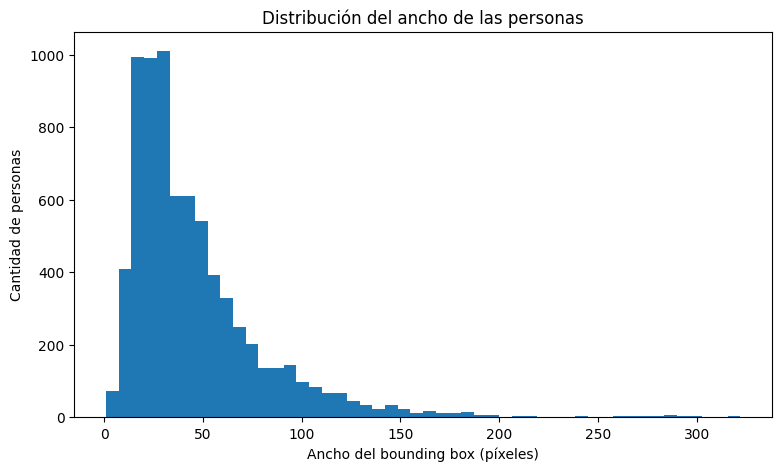

In [39]:
#distribucion del ancho de los bounding boxes en pixeles

plt.figure(figsize=(9,5))

plt.hist(
    df_boxes["width_px"],
    bins=50
)

plt.title("Distribución del ancho de las personas")
plt.xlabel("Ancho del bounding box (píxeles)")
plt.ylabel("Cantidad de personas")

plt.show()


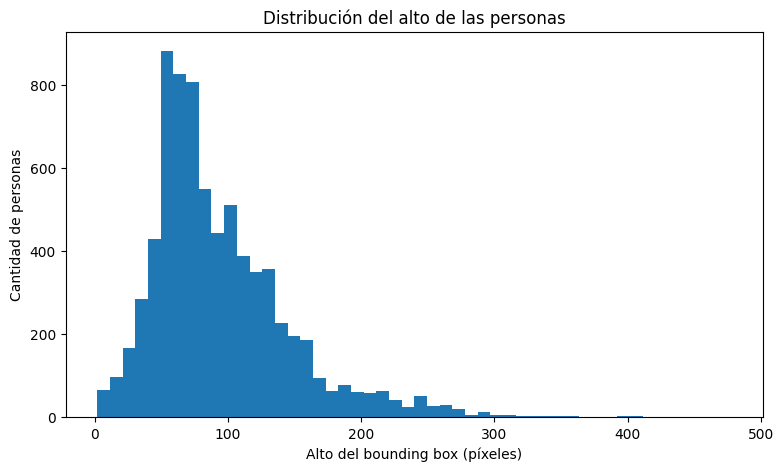

In [40]:
#distribucion del alto de los bounding boxes en pixeles

plt.figure(figsize=(9,5))

plt.hist(
    df_boxes["height_px"],
    bins=50
)

plt.title("Distribución del alto de las personas")
plt.xlabel("Alto del bounding box (píxeles)")
plt.ylabel("Cantidad de personas")

plt.show()


### Interpretación esperada

Después de ejecutar las celdas anteriores se debe interpretar:

* Qué porcentaje de los objetos ocupa menos del 1 % de la imagen.
* Cuál es el ancho y alto típico de una persona en píxeles.
* Si existen objetos extremadamente pequeños.
* Si train, validation y test presentan tamaños similares.

No se debe asumir que las personas son pequeñas solamente por observación visual; esta sección permite demostrarlo cuantitativamente.


## 3. Imágenes negativas: escenas sin personas

El valor mínimo de personas por imagen observado en el análisis anterior fue cero.

Estas imágenes no son necesariamente errores. En detección de objetos pueden funcionar como **ejemplos negativos**, ayudando al modelo a aprender que algunas escenas no contienen personas y reduciendo falsos positivos.


In [41]:
#contar imagenes con cero personas por particion

def contar_imagenes_negativas(ruta_labels):
    total = 0
    negativas = 0

    for archivo in ruta_labels.glob("*.txt"):
        total += 1

        with open(archivo, "r") as f:
            contenido = f.read().strip()

        if contenido == "":
            negativas += 1

    return total, negativas


for nombre, ruta in [
    ("TRAIN", ruta_train_lbl),
    ("VALID", ruta_valid_lbl),
    ("TEST", ruta_test_lbl)
]:

    total, negativas = contar_imagenes_negativas(ruta)

    porcentaje = negativas / total * 100 if total else 0

    print(f"{nombre}: {negativas}/{total} imágenes negativas ({porcentaje:.2f}%)")


TRAIN: 571/4041 imágenes negativas (14.13%)
VALID: 177/1144 imágenes negativas (15.47%)
TEST: 84/570 imágenes negativas (14.74%)


## 4. Revisión de posibles duplicados y fuga de información

Los nombres de archivo de esta exportación de Roboflow contienen un identificador de la imagen de origen seguido de un hash.

Se realizarán dos comprobaciones:

1. **Duplicados exactos:** imágenes con el mismo contenido binario.
2. **Solapamiento de identificadores de origen:** por ejemplo, variantes derivadas de `gss1200` que pudieran aparecer en particiones diferentes.

La segunda comprobación es especialmente importante porque dos imágenes aumentadas pueden no tener el mismo hash, pero sí proceder de la misma imagen original.


In [42]:
#funciones para detectar duplicados exactos y solapamiento de imagenes de origen

def hash_archivo(ruta, bloque=1024*1024):
    h = hashlib.md5()

    with open(ruta, "rb") as f:
        while True:
            datos = f.read(bloque)
            if not datos:
                break
            h.update(datos)

    return h.hexdigest()


def id_origen(nombre_archivo):
    #ejemplo: gss1200_jpg.rf.xxxxx.jpg -> gss1200
    nombre = Path(nombre_archivo).stem

    if "_jpg.rf." in nombre:
        return nombre.split("_jpg.rf.")[0]

    if ".rf." in nombre:
        return nombre.split(".rf.")[0]

    return nombre


def resumen_hashes(ruta_imagenes):
    registros = []

    for archivo in obtener_imagenes(ruta_imagenes):
        registros.append({
            "archivo": archivo.name,
            "hash": hash_archivo(archivo),
            "origen": id_origen(archivo.name)
        })

    return pd.DataFrame(registros)


hash_train = resumen_hashes(ruta_train_img)
hash_valid = resumen_hashes(ruta_valid_img)
hash_test = resumen_hashes(ruta_test_img)

print("==================================================")
print(" DUPLICADOS EXACTOS ENTRE PARTICIONES")
print("==================================================")

for nombre_a, df_a, nombre_b, df_b in [
    ("train", hash_train, "valid", hash_valid),
    ("train", hash_train, "test", hash_test),
    ("valid", hash_valid, "test", hash_test)
]:
    comunes = set(df_a["hash"]) & set(df_b["hash"])
    print(f"{nombre_a} vs {nombre_b}: {len(comunes)} hashes idénticos")


print("\n==================================================")
print(" SOLAPAMIENTO DE IDS DE ORIGEN")
print("==================================================")

for nombre_a, df_a, nombre_b, df_b in [
    ("train", hash_train, "valid", hash_valid),
    ("train", hash_train, "test", hash_test),
    ("valid", hash_valid, "test", hash_test)
]:
    comunes = set(df_a["origen"]) & set(df_b["origen"])
    print(f"{nombre_a} vs {nombre_b}: {len(comunes)} ids de origen compartidos")

    if comunes:
        print("Ejemplos:", sorted(list(comunes))[:10])


 DUPLICADOS EXACTOS ENTRE PARTICIONES
train vs valid: 0 hashes idénticos
train vs test: 0 hashes idénticos
valid vs test: 0 hashes idénticos

 SOLAPAMIENTO DE IDS DE ORIGEN
train vs valid: 0 ids de origen compartidos
train vs test: 0 ids de origen compartidos
valid vs test: 0 ids de origen compartidos


## 5. Archivo YAML corregido para el entrenamiento

El `data.yaml` incluido en la exportación contiene rutas relativas con `../`.

Como la estructura real fue verificada directamente en Colab, se generará un archivo YAML propio con una ruta base absoluta y rutas internas claras.

Esto evita depender de la ubicación desde la cual se interprete el YAML.


In [43]:
#crear un data.yaml propio con rutas verificadas

ruta_yaml_corregido = Path("/content/sard_data.yaml")

config_sard = {
    "path": str(ruta_base_sard),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": {
        0: "human"
    }
}

with open(ruta_yaml_corregido, "w") as archivo:
    yaml.safe_dump(
        config_sard,
        archivo,
        sort_keys=False,
        allow_unicode=True
    )

print("==================================================")
print(" YAML CORREGIDO")
print("==================================================")
print(f"Ruta: {ruta_yaml_corregido}\n")

with open(ruta_yaml_corregido, "r") as archivo:
    print(archivo.read())


 YAML CORREGIDO
Ruta: /content/sard_data.yaml

path: /kaggle/input/sard-search-and-rescue/search-and-rescue
train: train/images
val: valid/images
test: test/images
names:
  0: human



# Fase 2 — Baseline con YOLOv8n

El primer modelo práctico será **YOLOv8n**.

Se utiliza como baseline porque:

* Es una variante ligera.
* Permite transferencia de aprendizaje desde pesos preentrenados.
* Puede entrenarse rápidamente en una GPU como la Tesla T4.
* Proporciona directamente métricas estándar de detección.

El objetivo del baseline no es obtener inmediatamente el mejor modelo posible, sino establecer un punto de referencia reproducible para los experimentos posteriores.


In [ ]:
#configuracion del baseline YOLOv8n

dispositivo = 0 if torch.cuda.is_available() else "cpu"

modelo_yolo = YOLO("yolov8n.pt")

print("==================================================")
print(" BASELINE YOLOv8n")
print("==================================================")
print(f"Dispositivo: {dispositivo}")
print(f"Dataset: {ruta_yaml_corregido}")


 BASELINE YOLOv8n
Dispositivo: 0
Dataset: /content/sard_data.yaml


In [ ]:

from ultralytics import YOLO

# Cargamos el modelo base (o un last.pt si vas a retomar)
modelo_yolo = YOLO("yolov8n.pt")
# Al definir 'project' apuntando a tu Drive, los checkpoints (last.pt y best.pt)
# se guardarán solitos y de forma segura en tu nube.
resultados_train_yolo = modelo_yolo.train(
    data=str(ruta_yaml_corregido),
    epochs=50,
    imgsz=640,
    batch=16,
    device=dispositivo,
    patience=10,
    workers=2,
    project="/content/drive/MyDrive/IA2_SARD/runs_sard",  # <-- Aquí se guardan tus checkpoints en Drive
    name="yolov8n_baseline",
    seed=42,
    deterministic=True,
    plots=True,
    verbose=True
)


Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/sard_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_baseline-2, nbs=64, nms=None, opset=None, optimize=False,

## Evaluación de YOLOv8n sobre test

El conjunto de test no se utiliza para ajustar el modelo.

Una vez terminado el entrenamiento, se evaluará el checkpoint `best.pt` sobre test para obtener las métricas finales del baseline:

* Precision
* Recall
* mAP@50
* mAP@50-95


In [ ]:
#cargar el mejor checkpoint generado durante el entrenamiento
# Cambia esta línea para que apunte a tu Google Drive
ruta_best_yolo = Path("/content/drive/MyDrive/IA2_SARD/runs_sard/yolov8n_baseline-2/weights/best.pt")

modelo_yolo_best = YOLO(str(ruta_best_yolo))

# El resto de tu código se queda exactamente igual
metricas_yolo = modelo_yolo_best.val(
    data=str(ruta_yaml_corregido),
    split="test",
    imgsz=640,
    device=dispositivo,
    plots=True
)

resumen_yolo = pd.DataFrame([{
    "Modelo": "YOLOv8n",
    "Precision": float(metricas_yolo.box.mp),
    "Recall": float(metricas_yolo.box.mr),
    "mAP@50": float(metricas_yolo.box.map50),
    "mAP@50-95": float(metricas_yolo.box.map)
}])

resumen_yolo


Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 46.2±21.5 MB/s, size: 104.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /root/.cache/kagglehub/datasets/nikolasgegenava/sard-search-and-rescue/versions/1/search-and-rescue/test/labels... 570 images, 84 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 570/570 946.5it/s 0.6s
val: New cache created: /root/.cache/kagglehub/datasets/nikolasgegenava/sard-search-and-rescue/versions/1/search-and-rescue/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 4.5it/s 8.0s
                   all        570        732      0.965      0.874      0.934       0.62
Speed: 2.3ms preprocess, 4.5ms i

,Modelo,Precision,Recall,mAP@50,mAP@50-95
0,YOLOv8n,0.965405,0.874317,0.934302,0.620346


In [ ]:
#guardar las metricas del baseline para comparaciones posteriores

ruta_metricas = Path("/content/metricas_modelos.csv")

resumen_yolo.to_csv(
    ruta_metricas,
    index=False
)

print(f"Métricas guardadas en: {ruta_metricas}")


Métricas guardadas en: /content/metricas_modelos.csv



Curvas de entrenamiento y validación
/content/drive/MyDrive/clase/runs_sard/yolov8n_baseline-2/results.png


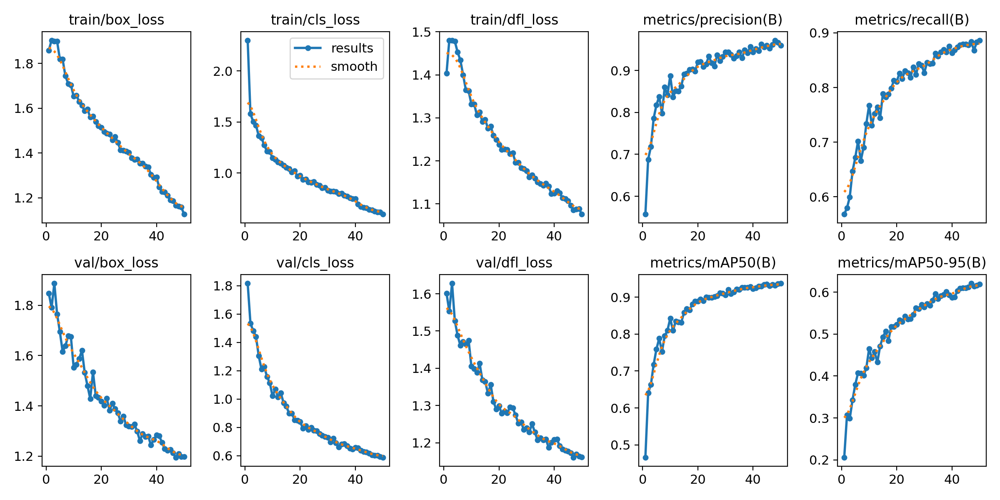


Matriz de confusión normalizada (validación)
/content/drive/MyDrive/clase/runs_sard/yolov8n_baseline-2/confusion_matrix_normalized.png


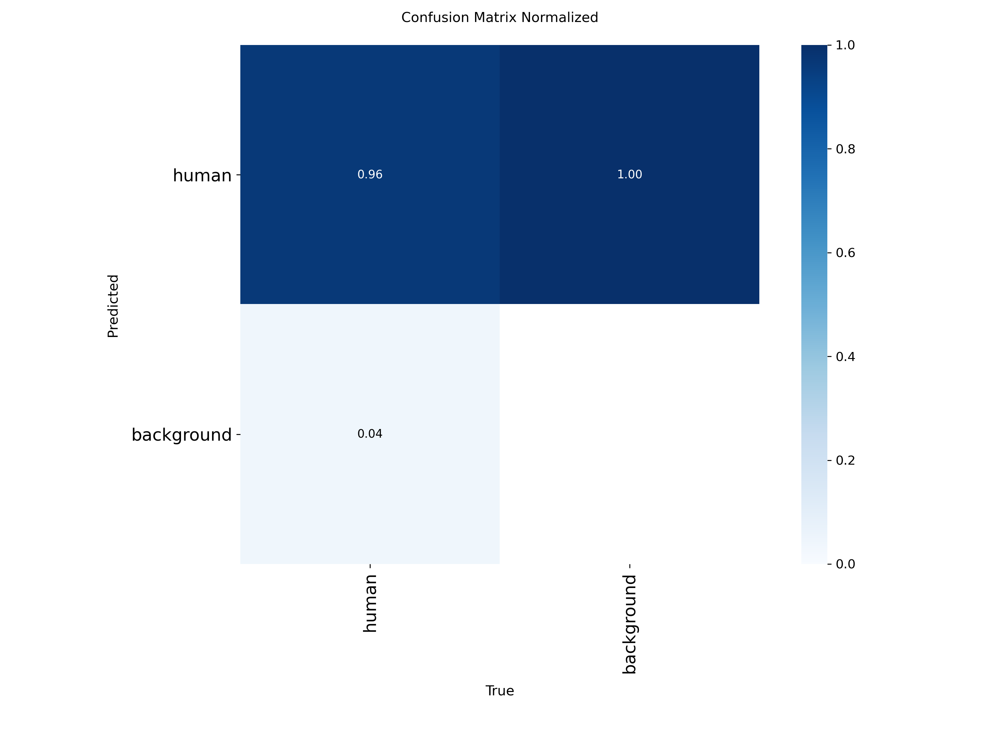


Curva Precision-Recall (test)
/content/runs/detect/val/BoxPR_curve.png


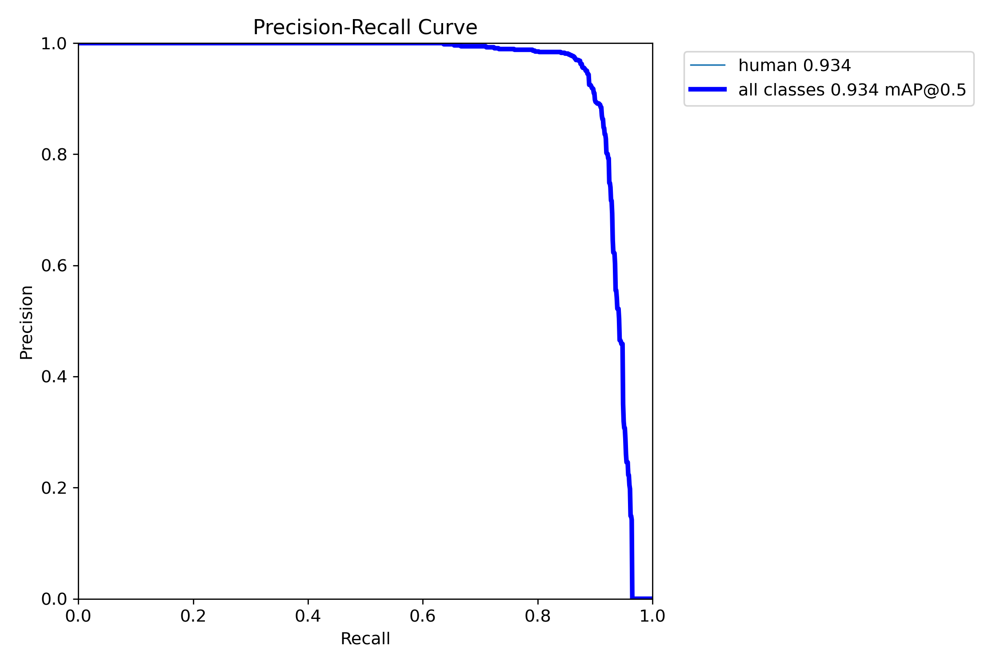


Curva F1 vs confianza (test)
/content/runs/detect/val/BoxF1_curve.png


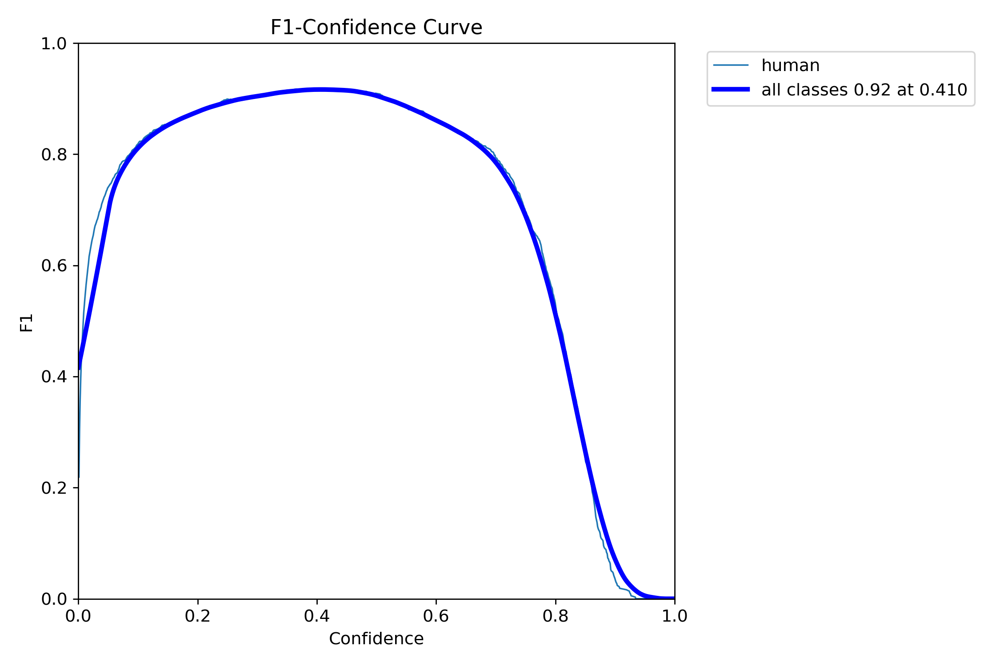


Matriz de confusión normalizada (test)
/content/runs/detect/val/confusion_matrix_normalized.png


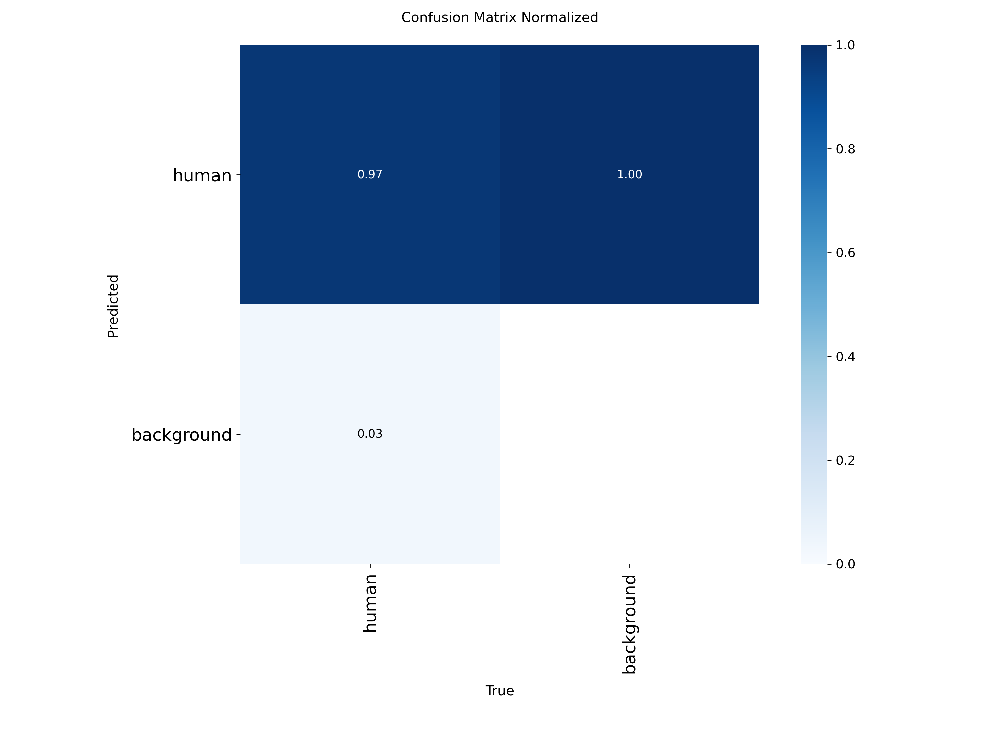

In [ ]:
##Visualizar curvas de entrenamiento
#mostrar las graficas que Ultralytics guardo durante el entrenamiento y la evaluacion en test

from IPython.display import Image as IPImage, display

ruta_run_yolo = Path("/content/drive/MyDrive/IA2_SARD/runs_sard/yolov8n_baseline-2")   # carpeta del entrenamiento
ruta_val_test = Path(metricas_yolo.save_dir)                                        # carpeta de la evaluacion en test

graficas = [
    (ruta_run_yolo, "results.png",                  "Curvas de entrenamiento y validación"),
    (ruta_run_yolo, "confusion_matrix_normalized.png", "Matriz de confusión normalizada (validación)"),
    (ruta_val_test, "BoxPR_curve.png",              "Curva Precision-Recall (test)"),
    (ruta_val_test, "BoxF1_curve.png",              "Curva F1 vs confianza (test)"),
    (ruta_val_test, "confusion_matrix_normalized.png", "Matriz de confusión normalizada (test)"),
]

for carpeta, nombre, titulo in graficas:
    archivo = carpeta / nombre
    if not archivo.exists():                       # algunas versiones usan PR_curve.png / F1_curve.png
        alternativa = carpeta / nombre.replace("Box", "")
        archivo = alternativa if alternativa.exists() else archivo
    if archivo.exists():
        print(f"\n{titulo}\n{archivo}")
        display(IPImage(filename=str(archivo), width=900))
    else:
        print(f"\nNo se encontró: {carpeta / nombre}")


## Predicciones cualitativas

Además de las métricas numéricas es importante observar ejemplos reales.

Se mostrarán predicciones sobre imágenes del conjunto de test para identificar:

* Detecciones correctas.
* Personas pequeñas correctamente encontradas.
* Falsos positivos.
* Falsos negativos.
* Escenas con múltiples personas.


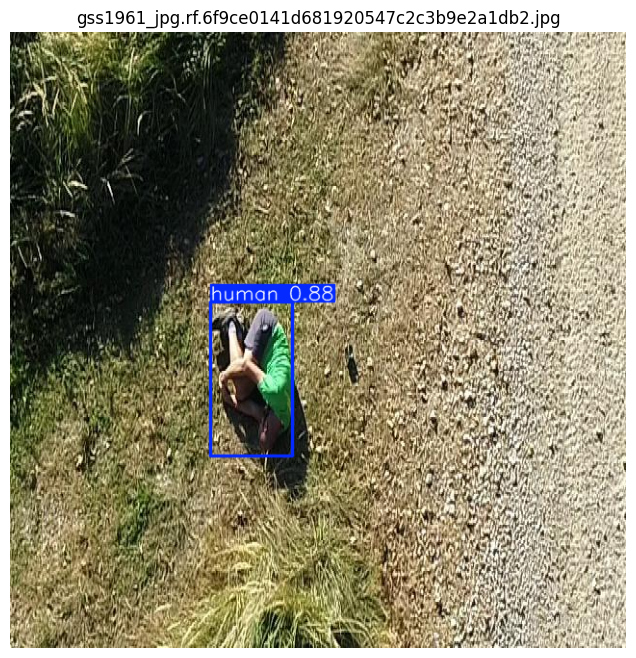

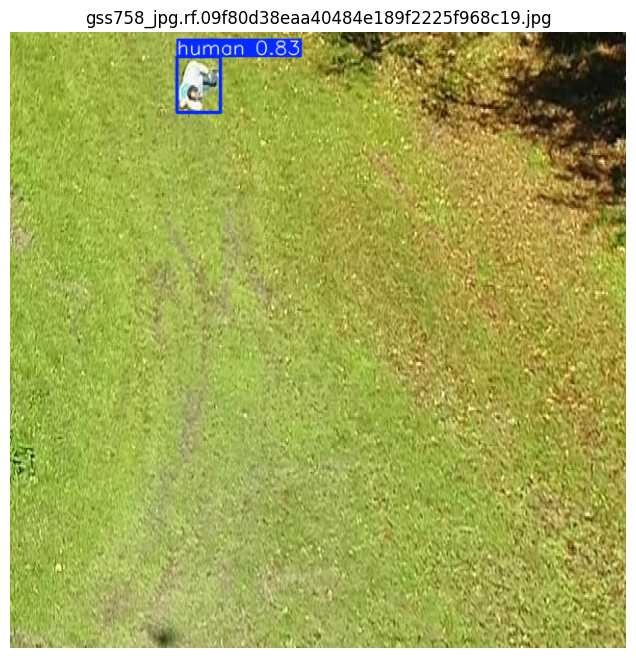

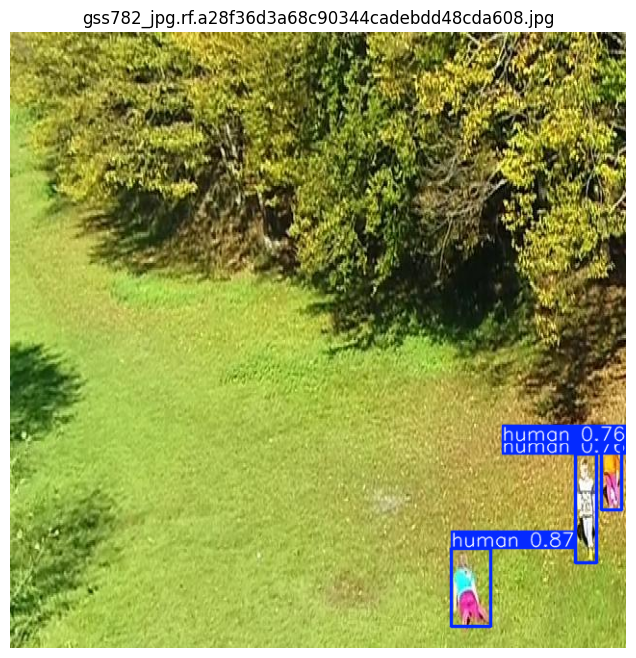

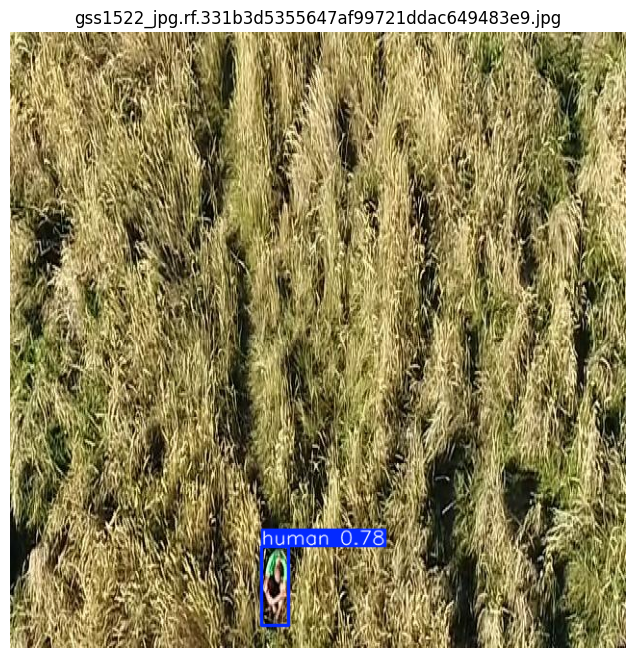

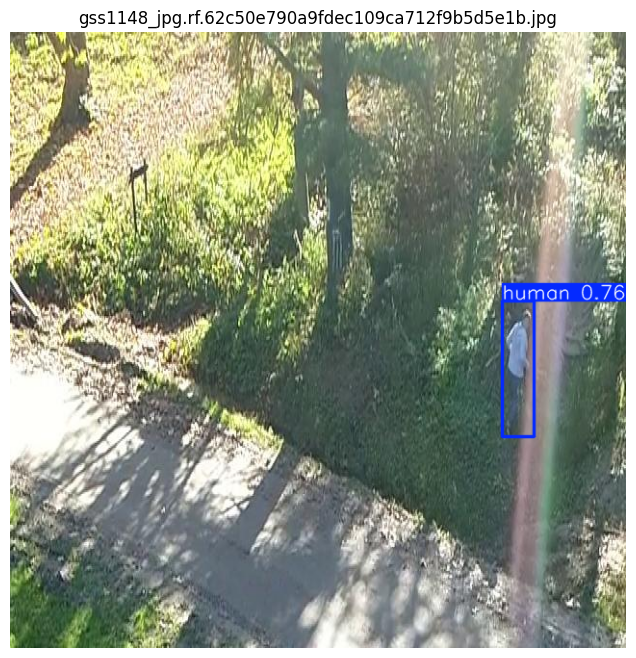

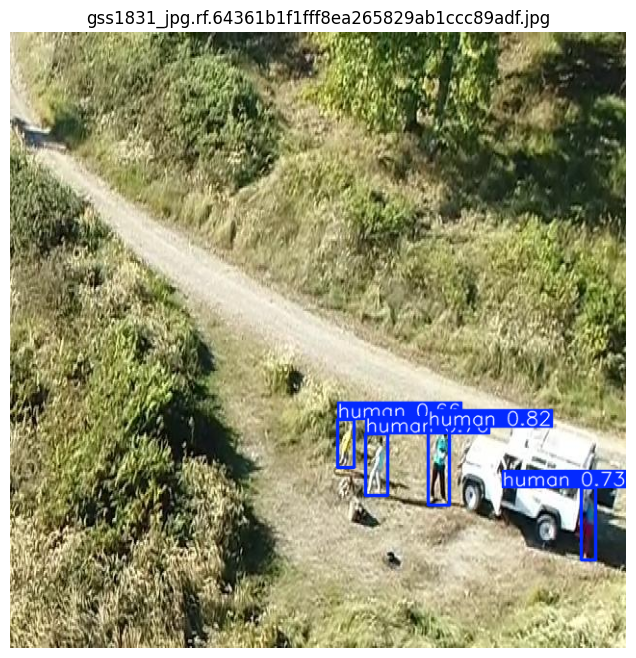

In [ ]:
#realizar predicciones sobre una muestra aleatoria del test

imagenes_test = obtener_imagenes(ruta_test_img)
muestras_test = random.sample(imagenes_test, min(6, len(imagenes_test)))

predicciones = modelo_yolo_best.predict(
    source=[str(x) for x in muestras_test],
    imgsz=640,
    conf=0.25,
    device=dispositivo,
    verbose=False
)

for resultado in predicciones:

    imagen_anotada = resultado.plot()

    plt.figure(figsize=(8,8))
    plt.imshow(imagen_anotada[..., ::-1])
    plt.title(Path(resultado.path).name)
    plt.axis("off")
    plt.show()


# Fase 3 — Faster R-CNN

Faster R-CNN será el segundo modelo de comparación.

A diferencia de YOLOv8, es un detector de dos etapas:

1. Una **Region Proposal Network (RPN)** genera regiones candidatas.
2. Las regiones se clasifican y sus bounding boxes se refinan.

Para mantener la comparación lo más consistente posible se utilizarán las mismas particiones de SARD.

En `torchvision`, la clase `0` se reserva para fondo, por lo que la clase `Human` se representará como `1`.


In [10]:
#instalar dependencias para evaluacion de Faster R-CNN

!pip install -q torchmetrics pycocotools


In [11]:
#importaciones para Faster R-CNN

from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchmetrics.detection.mean_ap import MeanAveragePrecision


In [12]:
#dataset personalizado que convierte labels YOLO a cajas XYXY

class SARDFasterRCNNDataset(Dataset):

    def __init__(self, ruta_imagenes, ruta_labels):
        self.ruta_imagenes = Path(ruta_imagenes)
        self.ruta_labels = Path(ruta_labels)
        self.imagenes = sorted(obtener_imagenes(self.ruta_imagenes))

    def __len__(self):
        return len(self.imagenes)

    def __getitem__(self, idx):

        imagen_path = self.imagenes[idx]
        label_path = self.ruta_labels / f"{imagen_path.stem}.txt"

        imagen = Image.open(imagen_path).convert("RGB")
        ancho_img, alto_img = imagen.size

        boxes = []
        labels = []

        if label_path.exists():

            with open(label_path, "r") as archivo:

                for linea in archivo:

                    if not linea.strip():
                        continue

                    clase, xc, yc, w, h = map(float, linea.split())

                    xc *= ancho_img
                    yc *= alto_img
                    w *= ancho_img
                    h *= alto_img

                    x1 = max(0, xc - w / 2)
                    y1 = max(0, yc - h / 2)
                    x2 = min(ancho_img, xc + w / 2)
                    y2 = min(alto_img, yc + h / 2)

                    if x2 > x1 and y2 > y1:
                        boxes.append([x1, y1, x2, y2])

                        #torchvision: 0 = background, 1 = Human
                        labels.append(1)

        if boxes:
            boxes = torch.tensor(boxes, dtype=torch.float32)
            labels = torch.tensor(labels, dtype=torch.int64)
        else:
            boxes = torch.zeros((0,4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([idx])
        }

        imagen = TF.to_tensor(imagen)

        return imagen, target


def collate_fn(batch):
    return tuple(zip(*batch))


In [44]:
#crear datasets y dataloaders

dataset_train_frcnn = SARDFasterRCNNDataset(
    ruta_train_img,
    ruta_train_lbl
)

dataset_valid_frcnn = SARDFasterRCNNDataset(
    ruta_valid_img,
    ruta_valid_lbl
)

dataset_test_frcnn = SARDFasterRCNNDataset(
    ruta_test_img,
    ruta_test_lbl
)

loader_train_frcnn = DataLoader(
    dataset_train_frcnn,
    batch_size=4,
    shuffle=True,
    num_workers=2,
    collate_fn=collate_fn
)

loader_valid_frcnn = DataLoader(
    dataset_valid_frcnn,
    batch_size=2,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_fn
)

loader_test_frcnn = DataLoader(
    dataset_test_frcnn,
    batch_size=2,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_fn
)

print(f"Train: {len(dataset_train_frcnn)}")
print(f"Valid: {len(dataset_valid_frcnn)}")
print(f"Test: {len(dataset_test_frcnn)}")


Train: 4041
Valid: 1144
Test: 570


In [45]:
#crear Faster R-CNN preentrenado y adaptar la cabeza a Human

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

modelo_frcnn = fasterrcnn_resnet50_fpn(
    weights="DEFAULT",
    min_size=640,
    max_size=640
)

in_features = modelo_frcnn.roi_heads.box_predictor.cls_score.in_features

modelo_frcnn.roi_heads.box_predictor = FastRCNNPredictor(
    in_features,
    num_classes=2
)

modelo_frcnn.to(device)

print(f"Modelo cargado en: {device}")


Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 196MB/s]


Modelo cargado en: cuda


In [46]:
#funcion de entrenamiento para una epoca

def entrenar_epoca_frcnn(modelo, loader, optimizador, device):

    modelo.train()

    perdida_total = 0

    for imagenes_batch, targets_batch in loader:

        imagenes_batch = [
            imagen.to(device)
            for imagen in imagenes_batch
        ]

        targets_batch = [
            {
                k: v.to(device)
                for k, v in target.items()
            }
            for target in targets_batch
        ]

        losses = modelo(
            imagenes_batch,
            targets_batch
        )

        loss = sum(valor for valor in losses.values())

        optimizador.zero_grad()
        loss.backward()
        optimizador.step()

        perdida_total += loss.item()

    return perdida_total / len(loader)


In [47]:
#entrenamiento inicial de Faster R-CNN
import time
from torchvision.ops import box_iou

# ---------- Carpeta de la corrida (igual a la de YOLO) ----------
RUTA_FRCNN = Path("/content/drive/MyDrive/IA2_SARD/runs_sard/faster_rcnn")
(RUTA_FRCNN / "weights").mkdir(parents=True, exist_ok=True)
ruta_last = RUTA_FRCNN / "weights" / "last.pth"
ruta_best = RUTA_FRCNN / "weights" / "best.pth"
ruta_csv  = RUTA_FRCNN / "results.csv"

# ---------- Train con hflip (imagen y cajas) ----------
class SARDTrainAug(SARDFasterRCNNDataset):
    def __getitem__(self, idx):
        img, t = super().__getitem__(idx)
        if random.random() < 0.5:
            w = img.shape[-1]
            img = img.flip(-1)
            if len(t["boxes"]):
                b = t["boxes"].clone()
                b[:, [0, 2]] = w - t["boxes"][:, [2, 0]]
                t["boxes"] = b
        return img, t

loader_train_frcnn = DataLoader(SARDTrainAug(ruta_train_img, ruta_train_lbl),
                                batch_size=4, shuffle=True, num_workers=2, collate_fn=collate_fn)

# ---------- Evaluación: mAP + Precision/Recall (score>=0.25, IoU>=0.5) + latencia ----------
@torch.no_grad()
def evaluar_completo(modelo, loader, device, score_thr=0.25, iou_thr=0.5):
    modelo.eval()
    m = MeanAveragePrecision(box_format="xyxy", iou_type="bbox")
    tp = fp = fn = 0
    t_inf, n_img = 0.0, 0
    for imgs, tgts in loader:
        imgs_g = [i.to(device) for i in imgs]
        torch.cuda.synchronize(); t0 = time.time()
        out = modelo(imgs_g)
        torch.cuda.synchronize(); t_inf += time.time() - t0; n_img += len(imgs)
        for o, t in zip(out, tgts):
            pb, ps, pl = o["boxes"].cpu(), o["scores"].cpu(), o["labels"].cpu()
            gb = t["boxes"]
            m.update([{"boxes": pb, "scores": ps, "labels": pl}],
                     [{"boxes": gb, "labels": t["labels"]}])
            pb = pb[ps >= score_thr]
            if len(gb) == 0: fp += len(pb); continue
            if len(pb) == 0: fn += len(gb); continue
            iou, usado = box_iou(pb, gb), set()
            for i in range(len(pb)):
                j = iou[i].clone()
                for u in usado: j[u] = -1
                best = j.argmax().item()
                if j[best] >= iou_thr: tp += 1; usado.add(best)
                else: fp += 1
            fn += len(gb) - len(usado)
    r = m.compute()
    return {"Precision": tp / max(tp + fp, 1), "Recall": tp / max(tp + fn, 1),
            "mAP@50": float(r["map_50"]), "mAP@50-95": float(r["map"]),
            "ms_por_imagen": 1000 * t_inf / n_img, "FPS": n_img / t_inf}


In [48]:
EPOCHS, PACIENCIA = 15, 5
params = [p for p in modelo_frcnn.parameters() if p.requires_grad]
optimizador_frcnn = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=0.0005)
scheduler_frcnn   = torch.optim.lr_scheduler.CosineAnnealingLR(optimizador_frcnn, T_max=EPOCHS)
scaler = torch.amp.GradScaler("cuda")

inicio, mejor_map, sin_mejora, historial = 0, -1.0, 0, []
if ruta_last.exists():
    ck = torch.load(ruta_last, map_location=device, weights_only=False)
    modelo_frcnn.load_state_dict(ck["model"])
    optimizador_frcnn.load_state_dict(ck["optimizer"])
    scheduler_frcnn.load_state_dict(ck["scheduler"])
    scaler.load_state_dict(ck["scaler"])
    inicio, mejor_map = ck["epoch"], ck["best_map"]
    sin_mejora, historial = ck["sin_mejora"], ck["historial"]
    print(f"↻ Retomando desde la época {inicio} (mejor mAP@50-95 val = {mejor_map:.4f})")

for epoch in range(inicio, EPOCHS):
    modelo_frcnn.train(); total = 0.0
    for imgs, tgts in loader_train_frcnn:
        imgs = [i.to(device) for i in imgs]
        tgts = [{k: v.to(device) for k, v in t.items()} for t in tgts]
        with torch.autocast("cuda"):
            loss = sum(modelo_frcnn(imgs, tgts).values())
        optimizador_frcnn.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(optimizador_frcnn); scaler.update()
        total += loss.item()
    scheduler_frcnn.step()

    val = evaluar_completo(modelo_frcnn, loader_valid_frcnn, device)
    historial.append({"epoch": epoch + 1, "loss_train": total / len(loader_train_frcnn),
                      **{f"val_{k}": v for k, v in val.items()}})
    print(f"Época {epoch+1}/{EPOCHS} | loss {historial[-1]['loss_train']:.4f} | "
          f"val mAP50 {val['mAP@50']:.4f} | mAP50-95 {val['mAP@50-95']:.4f} | "
          f"P {val['Precision']:.3f} | R {val['Recall']:.3f}")

    if val["mAP@50-95"] > mejor_map:                     # best.pth
        mejor_map, sin_mejora = val["mAP@50-95"], 0
        torch.save({"model": modelo_frcnn.state_dict(), "epoch": epoch + 1}, ruta_best)
    else:
        sin_mejora += 1

    torch.save({"model": modelo_frcnn.state_dict(),      # last.pth
                "optimizer": optimizador_frcnn.state_dict(),
                "scheduler": scheduler_frcnn.state_dict(), "scaler": scaler.state_dict(),
                "epoch": epoch + 1, "best_map": mejor_map, "sin_mejora": sin_mejora,
                "historial": historial}, ruta_last)
    pd.DataFrame(historial).to_csv(ruta_csv, index=False)   # results.csv

    if sin_mejora >= PACIENCIA:
        print(f"⏹ Early stopping: {PACIENCIA} épocas sin mejorar."); break


Época 1/15 | loss 0.1520 | val mAP50 0.8816 | mAP50-95 0.4809 | P 0.600 | R 0.899
Época 2/15 | loss 0.1240 | val mAP50 0.8954 | mAP50-95 0.5273 | P 0.702 | R 0.899
Época 3/15 | loss 0.1127 | val mAP50 0.9102 | mAP50-95 0.5311 | P 0.364 | R 0.927
Época 4/15 | loss 0.1062 | val mAP50 0.9149 | mAP50-95 0.5618 | P 0.605 | R 0.924
Época 5/15 | loss 0.0988 | val mAP50 0.9020 | mAP50-95 0.5691 | P 0.279 | R 0.910
Época 6/15 | loss 0.0928 | val mAP50 0.9133 | mAP50-95 0.5557 | P 0.539 | R 0.924
Época 7/15 | loss 0.0882 | val mAP50 0.9215 | mAP50-95 0.5844 | P 0.716 | R 0.926
Época 8/15 | loss 0.0820 | val mAP50 0.9118 | mAP50-95 0.5583 | P 0.722 | R 0.919
Época 9/15 | loss 0.0770 | val mAP50 0.9192 | mAP50-95 0.5613 | P 0.469 | R 0.934
Época 10/15 | loss 0.0708 | val mAP50 0.9071 | mAP50-95 0.5780 | P 0.852 | R 0.915
Época 11/15 | loss 0.0658 | val mAP50 0.9172 | mAP50-95 0.5883 | P 0.836 | R 0.924
Época 12/15 | loss 0.0613 | val mAP50 0.9172 | mAP50-95 0.5928 | P 0.852 | R 0.922
Época 13/15 |

In [49]:
#evaluar Faster R-CNN mediante mAP
ck_best = torch.load(ruta_best, map_location=device, weights_only=False)
modelo_frcnn.load_state_dict(ck_best["model"])
print(f"Mejor checkpoint: época {ck_best['epoch']}")

metricas_frcnn = evaluar_completo(modelo_frcnn, loader_test_frcnn, device)
resumen_frcnn = pd.DataFrame([{"Modelo": "Faster R-CNN", **metricas_frcnn}])
resumen_frcnn.to_csv(RUTA_FRCNN / "metricas_test.csv", index=False)
resumen_frcnn


Mejor checkpoint: época 12


,Modelo,Precision,Recall,mAP@50,mAP@50-95,ms_por_imagen,FPS
0,Faster R-CNN,0.814634,0.912568,0.908437,0.590038,85.057729,11.756721


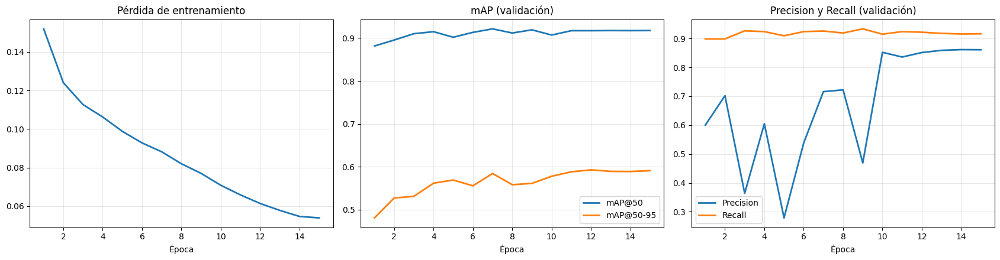

In [50]:
#Curvas de entrenamiento
df = pd.read_csv(ruta_csv)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

ax[0].plot(df["epoch"], df["loss_train"], lw=2); ax[0].set_title("Pérdida de entrenamiento")
ax[1].plot(df["epoch"], df["val_mAP@50"], lw=2, label="mAP@50")
ax[1].plot(df["epoch"], df["val_mAP@50-95"], lw=2, label="mAP@50-95"); ax[1].set_title("mAP (validación)")
ax[2].plot(df["epoch"], df["val_Precision"], lw=2, label="Precision")
ax[2].plot(df["epoch"], df["val_Recall"], lw=2, label="Recall"); ax[2].set_title("Precision y Recall (validación)")

for a in ax: a.set_xlabel("Época"); a.grid(alpha=0.3)
ax[1].legend(); ax[2].legend()
plt.tight_layout()
plt.savefig(RUTA_FRCNN / "results.png", dpi=150)     # queda en Drive
plt.show()


# Fase 4 — Viabilidad de Mask R-CNN

Mask R-CNN fue considerado durante el estado del arte como una posible extensión de Faster R-CNN.

Sin embargo, la revisión de SARD y SARD 2 confirmó que las anotaciones disponibles contienen únicamente **bounding boxes** en formato YOLO y no incluyen máscaras ni polígonos de segmentación por instancia.

Por esta razón, **Mask R-CNN no se implementa en la fase práctica**. Entrenarlo con máscaras rectangulares derivadas de las cajas no representaría la silueta real de las personas y haría que las métricas de segmentación fueran poco interpretables.

La decisión metodológica final del proyecto es:

- Implementar y comparar **YOLOv8n** y **Faster R-CNN**.
- Mantener **Mask R-CNN** como modelo analizado en el estado del arte.
- Documentar su no viabilidad con las anotaciones actuales.


In [54]:
#comprobar si existen archivos que parezcan mascaras de segmentacion
#comprobar si SARD o SARD 2 contienen anotaciones de segmentacion

def revisar_segmentacion(nombre, ruta_raiz):
    ruta_raiz = Path(ruta_raiz)

    # 1. archivos que parezcan mascaras o anotaciones tipo COCO
    candidatos = []
    for patron in ["*mask*", "*segment*", "*.json"]:
        candidatos.extend(ruta_raiz.rglob(patron))

    # 2. contenido real de los labels: caja = 5 campos; poligono = mas de 5
    n_caja = n_poligono = n_otro = 0
    for lbl in ruta_raiz.rglob("labels/*.txt"):
        with open(lbl, "r") as f:
            for linea in f:
                if not linea.strip():
                    continue
                n = len(linea.split())
                if n == 5:
                    n_caja += 1
                elif n > 5:
                    n_poligono += 1
                else:
                    n_otro += 1

    print("=" * 60)
    print(f" {nombre}")
    print("=" * 60)
    print(f"Archivos candidatos (mask/segment/json): {len(candidatos)}")
    print(f"Anotaciones tipo caja (5 campos):        {n_caja}")
    print(f"Anotaciones tipo poligono (>5 campos):   {n_poligono}")
    print(f"Anotaciones con formato raro (<5):       {n_otro}")

    for readme in sorted(ruta_raiz.rglob("README*"))[:2]:
        print(f"\n--- {readme.name} (primeras lineas) ---")
        print(readme.read_text(errors="ignore")[:500])

    return n_poligono

pol_sard  = revisar_segmentacion("SARD",   ruta_sard)
pol_sard2 = revisar_segmentacion("SARD 2", ruta_sard2)

if pol_sard == 0 and pol_sard2 == 0:
    print("\nConclusion: ningun dataset contiene mascaras ni poligonos; solo bounding boxes.")


 SARD
Archivos candidatos (mask/segment/json): 0
Anotaciones tipo caja (5 campos):        7424
Anotaciones tipo poligono (>5 campos):   0
Anotaciones con formato raro (<5):       0

--- README.dataset.txt (primeras lineas) ---
# Sard > TILES_3x3
https://universe.roboflow.com/datasets-pdabr/sard-8xjhy

Provided by a Roboflow user
License: undefined



--- README.roboflow.txt (primeras lineas) ---

Sard - v17 TILES_3x3

This dataset was exported via roboflow.com on April 7, 2025 at 10:08 AM GMT

Roboflow is an end-to-end computer vision platform that helps you
* collaborate with your team on computer vision projects
* collect & organize images
* understand and search unstructured image data
* annotate, and create datasets
* export, train, and deploy computer vision models
* use active learning to improve your dataset over time

For state of the art Computer 
 SARD 2
Archivos candidatos (mask/segment/json): 0
Anotaciones tipo caja (5 campos):        6354
Anotaciones tipo poligono (>5 camp

### Conclusión de la Fase 4: decisión sobre Mask R-CNN

La revisión de los dos conjuntos de datos mostró que ninguno contiene anotaciones de
segmentación:

| | SARD | SARD 2 |
|---|---:|---:|
| Archivos de máscaras o anotaciones tipo COCO | 0 | 0 |
| Anotaciones tipo caja (5 campos) | 7.424 | 6.354 |
| Anotaciones tipo polígono (más de 5 campos) | 0 | 0 |
| Anotaciones con formato irregular | 0 | 0 |

Todas las etiquetas corresponden a *bounding boxes* en formato YOLO
(`clase x_center y_center width height`).

**Por qué no se entrena Mask R-CNN.** Esta arquitectura necesita una máscara por
instancia para entrenar su rama de segmentación y para evaluarla. Con solo cajas habría
dos caminos, y ninguno es válido:

1. *Convertir cada caja en una máscara rectangular.* Esto no representa la silueta real
   de la persona, por lo que la rama de segmentación aprendería a reproducir la caja y
   no a segmentar. Además, cambiaría el significado de la tarea y las métricas de
   segmentación obtenidas no serían interpretables.
2. *Generar máscaras automáticamente con otro modelo.* Serían pseudo-etiquetas sin una
   referencia manual con la cual medir su calidad. Esto resulta especialmente delicado
   con objetos tan pequeños: la mediana de las personas anotadas mide unos 36 × 82 px,
   y el 63 % ocupa menos del 1 % de la imagen.


# Fase 5 — Análisis de SARD 2

SARD 2 se utilizará inicialmente como conjunto complementario.

Antes de mezclarlo con SARD se debe:

1. Revisar su archivo `data.yaml`.
2. Confirmar sus clases.
3. Contar imágenes y anotaciones.
4. Analizar la distribución de las posturas.
5. Comprobar qué imágenes o identificadores de origen se solapan con SARD.
6. Solo después decidir qué ejemplos pueden incorporarse al entrenamiento.


In [56]:
#definir ruta base de SARD 2

ruta_base_sard2 = Path(ruta_sard2) / "search-and-rescue-2"

ruta_sard2_yaml = ruta_base_sard2 / "data.yaml"

print("==================================================")
print(" DATA.YAML DE SARD 2")
print("==================================================")

with open(ruta_sard2_yaml, "r") as archivo:
    contenido_sard2_yaml = yaml.safe_load(archivo)

print(contenido_sard2_yaml)


 DATA.YAML DE SARD 2
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 6, 'names': ['Running', 'Walking', 'laying_down', 'not_defined', 'seated', 'stands'], 'roboflow': {'workspace': 'rescuedby', 'project': 'sard-peykp-lxuf9', 'version': 1, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/rescuedby/sard-peykp-lxuf9/dataset/1'}}


In [57]:
#contar clases presentes en SARD 2

rutas_sard2 = {
    "train": {
        "images": ruta_base_sard2 / "train" / "images",
        "labels": ruta_base_sard2 / "train" / "labels"
    },
    "valid": {
        "images": ruta_base_sard2 / "valid" / "images",
        "labels": ruta_base_sard2 / "valid" / "labels"
    },
    "test": {
        "images": ruta_base_sard2 / "test" / "images",
        "labels": ruta_base_sard2 / "test" / "labels"
    }
}

nombres_sard2 = contenido_sard2_yaml.get("names", {})

if isinstance(nombres_sard2, list):
    mapa_nombres_sard2 = {
        i: nombre
        for i, nombre in enumerate(nombres_sard2)
    }
else:
    mapa_nombres_sard2 = {
        int(k): v
        for k, v in nombres_sard2.items()
    }

registros_clases_sard2 = []

for particion, rutas in rutas_sard2.items():

    for archivo in rutas["labels"].glob("*.txt"):

        with open(archivo, "r") as f:

            for linea in f:

                if not linea.strip():
                    continue

                clase = int(float(linea.split()[0]))

                registros_clases_sard2.append({
                    "particion": particion,
                    "clase_id": clase,
                    "clase": mapa_nombres_sard2.get(clase, str(clase))
                })

df_clases_sard2 = pd.DataFrame(registros_clases_sard2)

print("==================================================")
print(" DISTRIBUCIÓN DE CLASES SARD 2")
print("==================================================")

display(
    pd.crosstab(
        df_clases_sard2["clase"],
        df_clases_sard2["particion"]
    )
)


 DISTRIBUCIÓN DE CLASES SARD 2


particion,test,train,valid
clase,,,
Running,9,44,25
Walking,115,907,266
laying_down,151,1096,322
not_defined,89,698,189
seated,69,414,138
stands,185,1265,372


In [58]:
#comparar identificadores de origen entre SARD y SARD 2

ids_sard = set()

for ruta in [
    ruta_train_img,
    ruta_valid_img,
    ruta_test_img
]:
    ids_sard.update(
        id_origen(x.name)
        for x in obtener_imagenes(ruta)
    )

ids_sard2 = set()

for particion in rutas_sard2.values():
    ids_sard2.update(
        id_origen(x.name)
        for x in obtener_imagenes(particion["images"])
    )

ids_compartidos = ids_sard & ids_sard2

print("==================================================")
print(" SOLAPAMIENTO SARD vs SARD 2")
print("==================================================")

print(f"IDs de origen SARD: {len(ids_sard)}")
print(f"IDs de origen SARD 2: {len(ids_sard2)}")
print(f"IDs compartidos: {len(ids_compartidos)}")

if ids_compartidos:
    print("Ejemplos:", sorted(list(ids_compartidos))[:20])


 SOLAPAMIENTO SARD vs SARD 2
IDs de origen SARD: 1980
IDs de origen SARD 2: 1980
IDs compartidos: 1979
Ejemplos: ['gss1', 'gss10', 'gss100', 'gss1006', 'gss1007', 'gss1008', 'gss1009', 'gss101', 'gss1010', 'gss1011', 'gss1012', 'gss1013', 'gss1014', 'gss1015', 'gss1016', 'gss1017', 'gss1018', 'gss1019', 'gss102', 'gss1020']


In [59]:
#resumen de SARD 2: imagenes, cajas, negativas, tamaño y estructura de ids

filas = []
for part, r in rutas_sard2.items():
    imgs = obtener_imagenes(r["images"])
    n_box, n_neg, areas = 0, 0, []
    for lbl in r["labels"].glob("*.txt"):
        lineas = [l.split() for l in open(lbl) if l.strip()]
        n_box += len(lineas)
        n_neg += (len(lineas) == 0)
        areas += [float(p[3]) * float(p[4]) * 100 for p in lineas if len(p) == 5]
    ids = pd.Series([id_origen(x.name) for x in imgs]).value_counts()
    filas.append({"particion": part, "imagenes": len(imgs), "cajas": n_box,
                  "imgs_negativas": n_neg, "mediana_area_%": round(np.median(areas), 3),
                  "ids_origen": ids.size, "mediana_img_por_id": ids.median()})

display(pd.DataFrame(filas))
print(f"SARD (referencia): mediana de área = {df_boxes['area_pct'].median():.3f} %")
print("Ejemplos de nombres en SARD 2:",
      [x.name for x in obtener_imagenes(rutas_sard2['train']['images'])[:3]])


,particion,imagenes,cajas,imgs_negativas,mediana_area_%,ids_origen,mediana_img_por_id
0,train,1386,4424,2,0.089,1386,1.0
1,valid,396,1312,2,0.084,396,1.0
2,test,198,618,0,0.084,198,1.0


SARD (referencia): mediana de área = 0.698 %
Ejemplos de nombres en SARD 2: ['gss556_jpg.rf.4f31b9ac32e1121de1477081e5689c61.jpg', 'gss1344_jpg.rf.4300d5bc61fe8e1b4bcdb3b90b3c491d.jpg', 'gss387_jpg.rf.8a079345a7ca984ef2cd6632dd64297f.jpg']


In [60]:
#similitud visual (dHash) entre SARD 2 y las particiones de SARD
from tqdm.auto import tqdm

RUTA_DF_S2 = Path("/content/drive/MyDrive/IA2_SARD/runs_sard/sard2_similitud.csv")

def dhash(ruta, tam=16):
    with Image.open(ruta) as im:
        g = im.convert("L").resize((tam + 1, tam), Image.BILINEAR)
    a = np.asarray(g, dtype=np.int16)
    return np.packbits((a[:, 1:] > a[:, :-1]).flatten())        # 256 bits -> 32 bytes

def hashes_carpeta(ruta_imgs):
    archivos = sorted(obtener_imagenes(ruta_imgs))
    H = np.stack([dhash(a) for a in tqdm(archivos, leave=False)])
    return archivos, H

POPCOUNT = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)

def distancia_minima(Hq, Href):
    """Distancia de Hamming minima de cada hash de Hq contra Href."""
    out = np.empty(len(Hq), dtype=np.int32)
    for i, h in enumerate(Hq):
        out[i] = POPCOUNT[np.bitwise_xor(Href, h)].sum(axis=1).min()
    return out

if RUTA_DF_S2.exists():
    df_s2 = pd.read_csv(RUTA_DF_S2)
    print("Cargado desde Drive:", len(df_s2), "imágenes de SARD 2")
else:
    ref = {n: hashes_carpeta(r) for n, r in [("train", ruta_train_img),
                                             ("valid", ruta_valid_img),
                                             ("test",  ruta_test_img)]}
    H_vt = np.concatenate([ref["valid"][1], ref["test"][1]])
    H_tr = ref["train"][1]

    filas = []
    for part, r in rutas_sard2.items():
        arch, H = hashes_carpeta(r["images"])
        d_vt, d_tr = distancia_minima(H, H_vt), distancia_minima(H, H_tr)
        for a, dv, dt in zip(arch, d_vt, d_tr):
            filas.append({"particion_s2": part, "ruta": str(a), "archivo": a.name,
                          "d_valid_test": int(dv), "d_train": int(dt)})
    df_s2 = pd.DataFrame(filas)
    df_s2.to_csv(RUTA_DF_S2, index=False)

print("\nImágenes de SARD 2 con una imagen casi idéntica en SARD (distancia de Hamming, de 256 bits):")
for thr in [0, 5, 10, 20]:
    print(f"  d <= {thr:>2} | valid/test de SARD: {(df_s2.d_valid_test <= thr).sum():>5} "
          f"| train de SARD: {(df_s2.d_train <= thr).sum():>5}  (de {len(df_s2)})")


  0%|          | 0/4041 [00:00<?, ?it/s]

  0%|          | 0/1144 [00:00<?, ?it/s]

  0%|          | 0/570 [00:00<?, ?it/s]

  0%|          | 0/1386 [00:00<?, ?it/s]

  0%|          | 0/396 [00:00<?, ?it/s]

  0%|          | 0/198 [00:00<?, ?it/s]


Imágenes de SARD 2 con una imagen casi idéntica en SARD (distancia de Hamming, de 256 bits):
  d <=  0 | valid/test de SARD:     0 | train de SARD:     0  (de 1980)
  d <=  5 | valid/test de SARD:     0 | train de SARD:     0  (de 1980)
  d <= 10 | valid/test de SARD:     0 | train de SARD:     0  (de 1980)
  d <= 20 | valid/test de SARD:     0 | train de SARD:     0  (de 1980)


In [61]:
#construir SARD 2 filtrado (sin solapamiento con valid/test) y remapeado a Human

UMBRAL_VT = 10        # excluir si es casi igual a una imagen de valid/test de SARD
UMBRAL_TR = 5         # excluir si es casi duplicado de train (no aporta informacion nueva)
CLASES_EXCLUIR = set()   # ids de clase de SARD 2 que NO son personas, p. ej. {3}

RUTA_MIX = Path("/content/sard2_filtrado")
for sub in ["images", "labels"]:
    (RUTA_MIX / sub).mkdir(parents=True, exist_ok=True)

validas = df_s2[(df_s2.d_valid_test > UMBRAL_VT) & (df_s2.d_train > UMBRAL_TR)]

n_img, n_cajas = 0, 0
for _, f in validas.iterrows():
    src = Path(f.ruta)
    lbl = rutas_sard2[f.particion_s2]["labels"] / f"{src.stem}.txt"
    nuevo = f"s2_{f.particion_s2}_{src.stem}"          # prefijo para evitar choques de nombres

    lineas = []
    if lbl.exists():
        for l in open(lbl):
            p = l.split()
            if len(p) == 5 and int(float(p[0])) not in CLASES_EXCLUIR:
                lineas.append("0 " + " ".join(p[1:]))   # todas -> human

    shutil.copy2(src, RUTA_MIX / "images" / f"{nuevo}{src.suffix}")
    (RUTA_MIX / "labels" / f"{nuevo}.txt").write_text("\n".join(lineas) + ("\n" if lineas else ""))
    n_img += 1; n_cajas += len(lineas)

print(f"SARD 2 total: {len(df_s2)} imágenes")
print(f"Incorporables: {n_img} imágenes | {n_cajas} cajas")
print(f"Descartadas por solapamiento o duplicado: {len(df_s2) - n_img}")

# YAML de la mezcla: train = SARD train + SARD 2 filtrado; valid y test siguen siendo SARD
ruta_yaml_mix = Path("/content/sard_mix_data.yaml")
config_mix = {"train": [str(ruta_train_img), str(RUTA_MIX / "images")],
              "val":   str(ruta_valid_img),
              "test":  str(ruta_test_img),
              "names": {0: "human"}}
with open(ruta_yaml_mix, "w") as f:
    yaml.safe_dump(config_mix, f, sort_keys=False)
shutil.copy2(ruta_yaml_mix, "/content/drive/MyDrive/IA2_SARD/runs_sard/sard_mix_data.yaml")
print(open(ruta_yaml_mix).read())


SARD 2 total: 1980 imágenes
Incorporables: 1980 imágenes | 6354 cajas
Descartadas por solapamiento o duplicado: 0
train:
- /kaggle/input/sard-search-and-rescue/search-and-rescue/train/images
- /content/sard2_filtrado/images
val: /kaggle/input/sard-search-and-rescue/search-and-rescue/valid/images
test: /kaggle/input/sard-search-and-rescue/search-and-rescue/test/images
names:
  0: human



## Decisión sobre SARD 2

SARD 2 fue analizado como posible conjunto complementario. Sin embargo, la comparación de identificadores de origen mostró un solapamiento muy alto con SARD:

- IDs de origen en SARD: 1.980
- IDs de origen en SARD 2: 1.980
- IDs compartidos: 1.979

Debido al riesgo de introducir escenas derivadas o información redundante entre particiones, **SARD 2 no se incorpora al experimento final de esta entrega**.

Los resultados comparativos reportados corresponden únicamente a modelos entrenados y evaluados con las particiones originales de SARD.


# Fase 6 — Comparación final

Los resultados finales sobre el conjunto de prueba de SARD son:

| Modelo | Precision | Recall | mAP@50 | mAP@50-95 | Velocidad |
|---|---:|---:|---:|---:|---:|
| YOLOv8n | **0.9654** | 0.8743 | **0.9343** | **0.6203** | ≈ 4.5 ms/imagen* |
| Faster R-CNN | 0.8146 | **0.9126** | 0.9084 | 0.5900 | 85.06 ms/imagen / 11.76 FPS |

\*La velocidad de YOLO corresponde a la inferencia reportada por Ultralytics; para una comparación estricta de rendimiento ambos modelos deben cronometrarse con el mismo protocolo.

### Interpretación

- **YOLOv8n** obtuvo la mayor Precision y los mayores valores de mAP, además de una inferencia considerablemente más rápida.
- **Faster R-CNN** obtuvo el mayor Recall, lo que indica que encontró una mayor proporción de las personas presentes.
- Para el escenario evaluado, **YOLOv8n ofrece el mejor equilibrio global entre precisión, calidad de detección y velocidad**.
- El mayor Recall de Faster R-CNN sigue siendo relevante en búsqueda y rescate, donde un falso negativo corresponde a una persona no detectada.


# Conclusiones y trabajo restante

1. Se validó la integridad de SARD y se confirmó que la exportación utilizada contiene 5.755 imágenes a 640×640.
2. El 63,44 % de las personas anotadas ocupa menos del 1 % del área total de la imagen, confirmando la dificultad de detectar objetos pequeños.
3. YOLOv8n presentó el mejor equilibrio general entre Precision, mAP y velocidad.
4. Faster R-CNN presentó un Recall superior, característica importante en un contexto de búsqueda y rescate.
5. Mask R-CNN no se implementó porque SARD y SARD 2 no contienen máscaras de segmentación por instancia.
6. SARD 2 fue analizado, pero no se incorporó al experimento final debido al alto solapamiento de identificadores de origen con SARD.

### Trabajo restante

- Analizar falsos positivos y falsos negativos de ambos modelos.
- Profundizar en el desempeño sobre personas de tamaño reducido.
- Estandarizar la medición de velocidad entre modelos bajo el mismo protocolo.
- Consolidar la documentación, presentación y conclusiones para la entrega final.
